# **🛒 Segmentación de clientes con K-Means y RFM**
¿Todos los clientes de una tienda online compran igual? En este proyecto analizamos las ventas de un e-commerce para descubrir **qué tipos de clientes hay**, usando un algoritmo que agrupa clientes parecidos (**K-Means**) y tres números que resumen cómo compra cada uno (**RFM**).

---

**🧭 Qué vas a encontrar**

* 📥 **Datos:** carga e inspección de más de 500.000 registros de ventas.
* 🧹 **Limpieza:** paso a paso, explicando cada decisión.
* 🧮 **RFM:** un perfil de tres números por cliente.
* 📐 **Preparación:** transformar los datos para que el algoritmo funcione bien.
* 🎯 **Elección de k:** cuántos grupos conviene formar, con respaldo de datos.
* 🏷️ **Segmentos:** quiénes son, cuánto pesan y qué hacer con cada uno.

---

**▶️ Cómo usar este notebook**

* Ejecutá las celdas **en orden** (Entorno de ejecución → Ejecutar todo).
* Cada sección empieza con una explicación breve y sigue con el código comentado.
* El detalle del proyecto está en el **README** del repositorio.

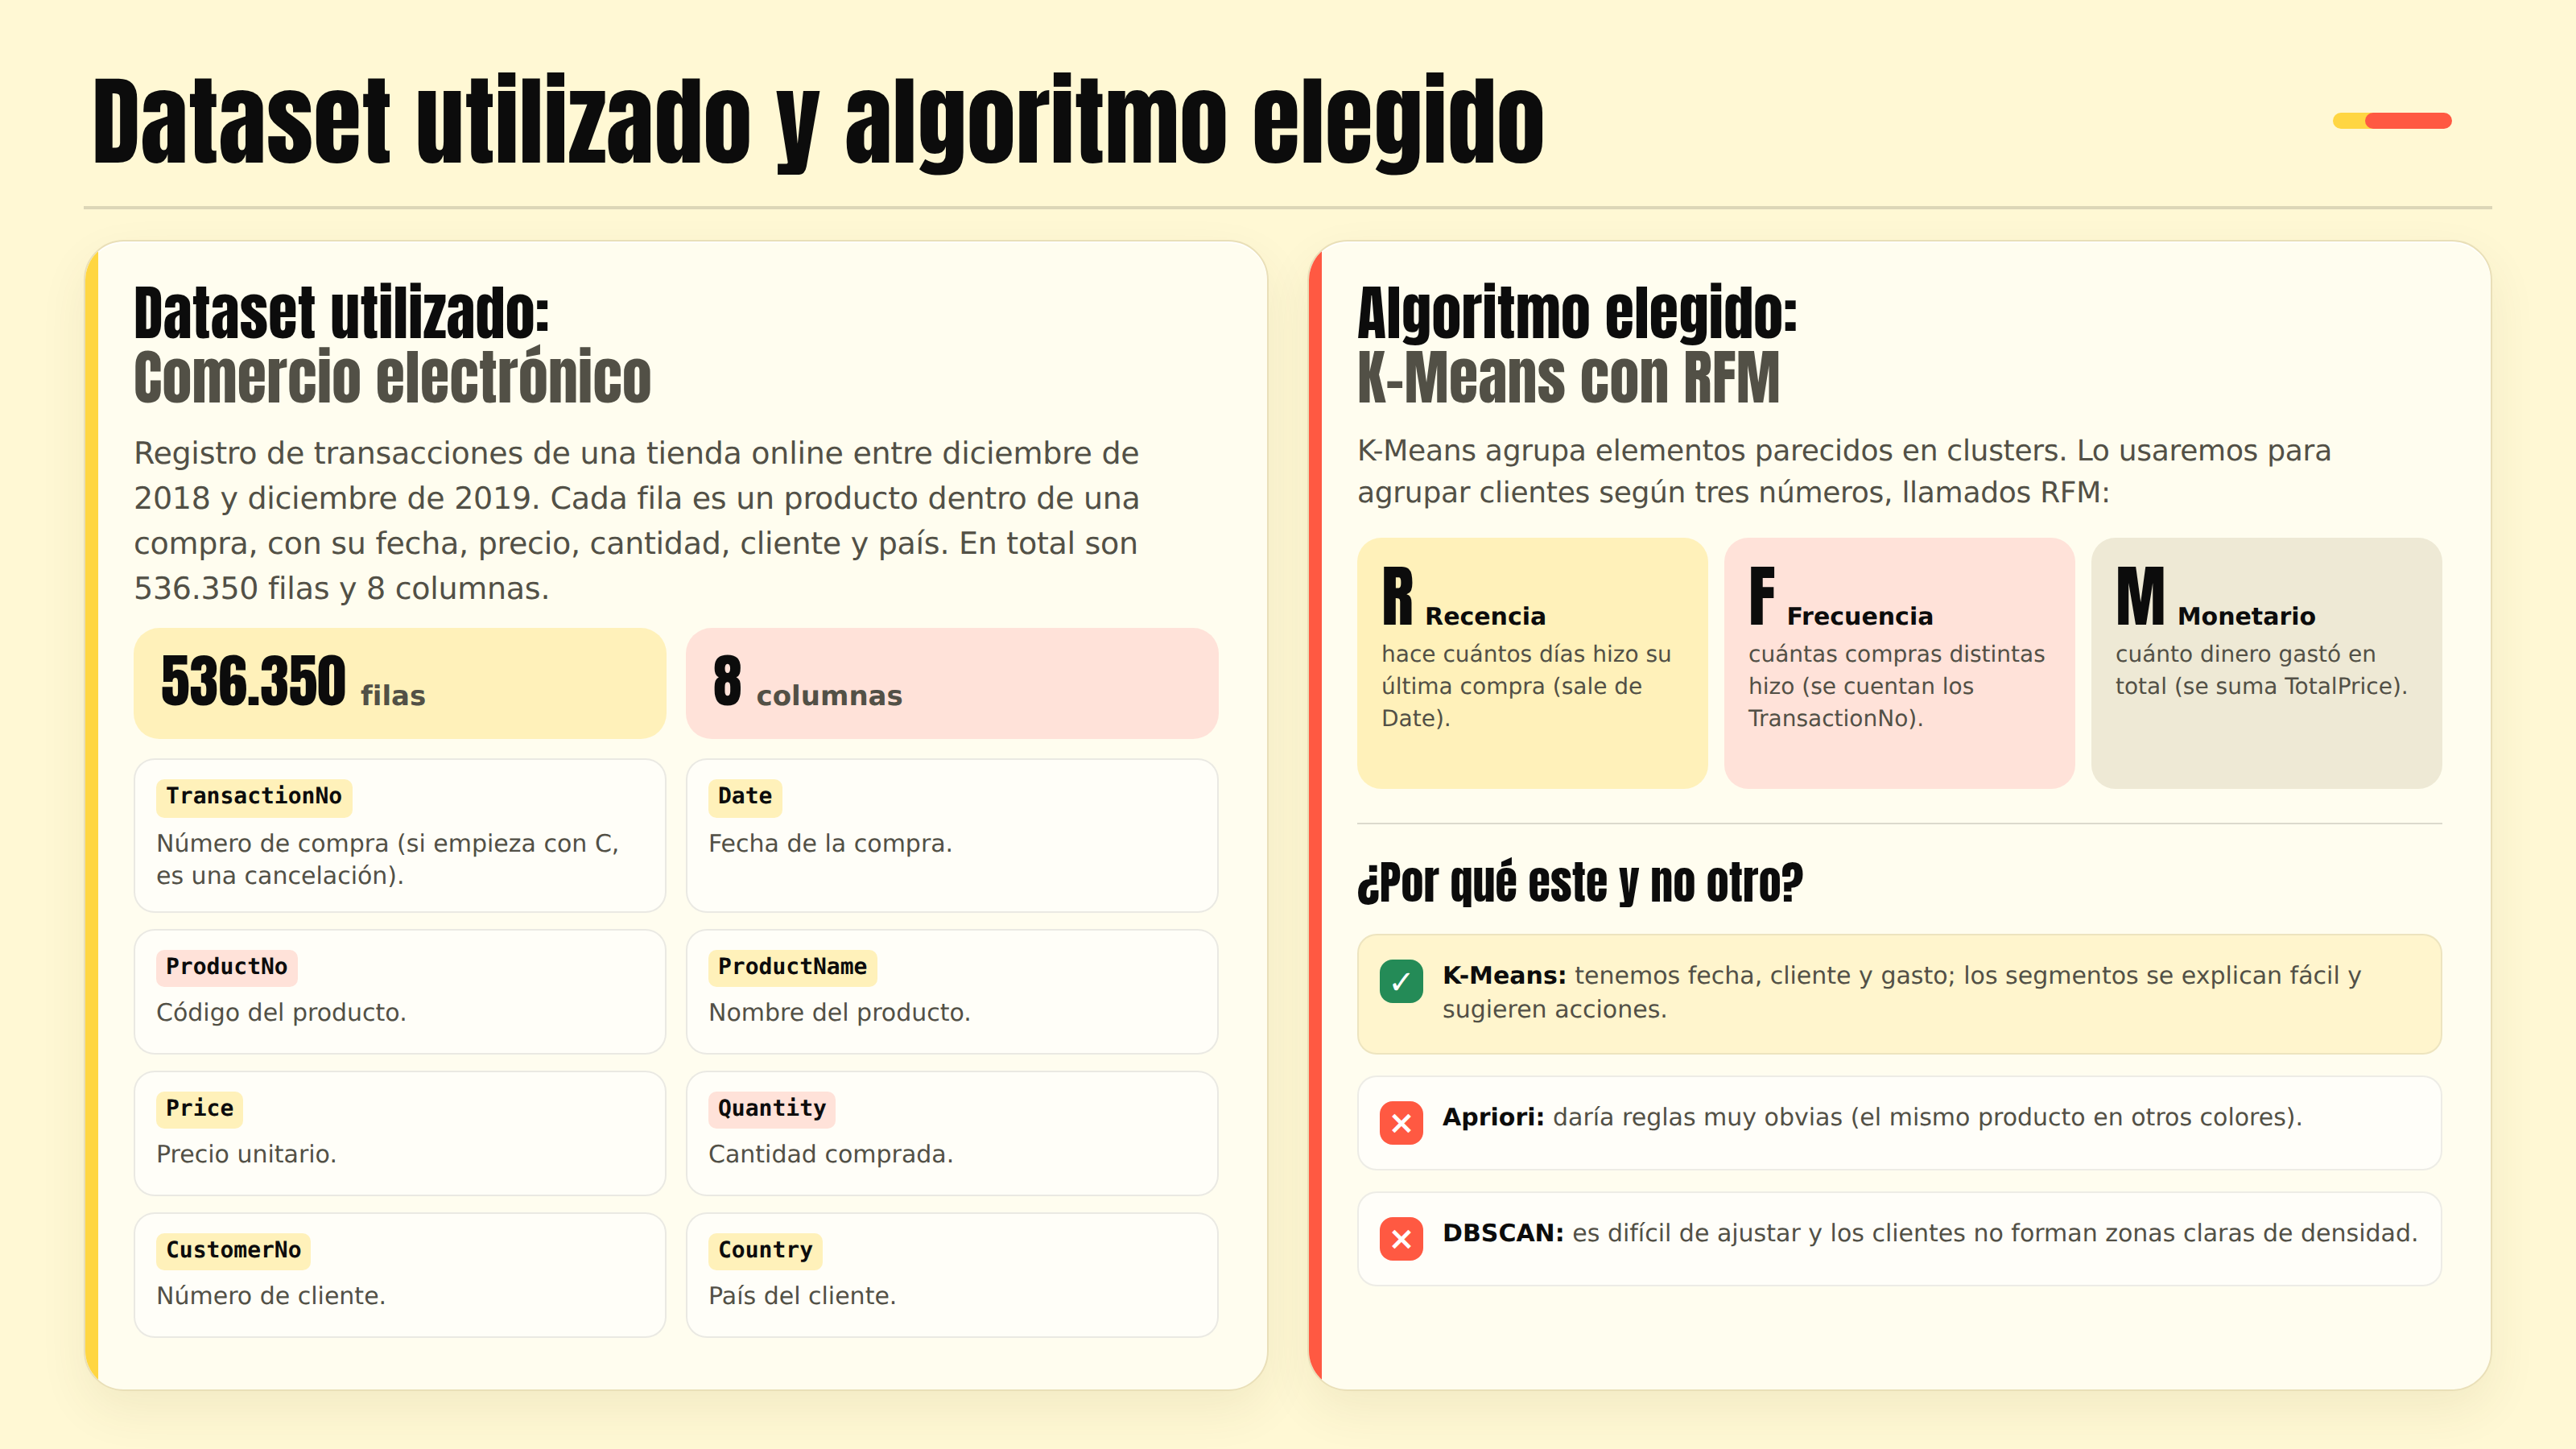

### **1️⃣ Carga de Datos**
Preparamos el entorno y leemos el archivo CSV para convertirlo en un DataFrame, una tabla que podemos consultar, filtrar y transformar.

---

**🎯 Objetivos:**
* 🧰 Dejar listo el entorno con todas las librerías necesarias.
* 📥 Cargar el dataset completo sin errores ni pérdida de datos.
* 👀 Confirmar que las columnas y los datos se vean correctamente.
* 📏 Conocer el tamaño inicial del dataset en filas y columnas.

In [ ]:
# Importamos pandas para trabajar con tablas (DataFrames)
import pandas as pd

# Importamos numpy para hacer cálculos numéricos
import numpy as np

# Importamos matplotlib para crear gráficos
import matplotlib.pyplot as plt

# Importamos Plotly Express para los gráficos interactivos
import plotly.express as px

# Importamos Plotly Graph Objects para personalizar los gráficos 3D
import plotly.graph_objects as go

# Importamos la herramienta para dibujar varios gráficos 3D en una sola figura
from plotly.subplots import make_subplots

# Le pedimos a pandas que muestre todas las columnas al imprimir una tabla
pd.set_option("display.max_columns", None)

In [ ]:
# Dirección del archivo de datos en GitHub.
ruta_csv = "https://raw.githubusercontent.com/bentadev/segmentacion-clientes-kmeans/main/data/comercio_electronico.zip"

# Si trabajás en tu computadora, usá el archivo local: quitá el "#" de la siguiente línea
# ruta_csv = "../data/comercio_electronico.zip"

# Leemos el archivo (pandas lee el .zip directamente) y lo guardamos en la variable df
df = pd.read_csv(ruta_csv)

# Mostramos cuántas filas y columnas tiene el dataset
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

# Mostramos las primeras 5 filas
df.head()

Filas: 536350 | Columnas: 8


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.0,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom


### **2️⃣ Inspección de Datos**
Revisamos el dataset sin modificarlo: tipos de dato, estadísticas, valores vacíos, filas repetidas y casos extremos. Esta etapa es solo de observación; lo que encontremos será la lista de tareas para la limpieza.

---

**🎯 Objetivos:**
* 🧱 Verificar que cada columna tenga el tipo de dato correcto.
* 🕳️ Detectar si hay valores vacíos y en qué columnas están.
* 🚨 Localizar valores extremos que puedan afectar a los algoritmos.

In [ ]:
# Mostramos el tipo de dato de cada columna y cuántos valores no nulos tiene
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           536350 non-null  object 
 2   ProductNo      536350 non-null  object 
 3   ProductName    536350 non-null  object 
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.7+ MB


In [ ]:
# Calculamos mínimo, máximo, promedio y cuartiles de las columnas numéricas
df.describe()

,Price,Quantity,CustomerNo
count,536350.000000,536350.000000,536295.000000
mean,12.662182,9.919347,15227.893178
std,8.490450,216.662300,1716.582932
min,5.130000,-80995.000000,12004.000000
25%,10.990000,1.000000,13807.000000
50%,11.940000,3.000000,15152.000000
75%,14.090000,10.000000,16729.000000
max,660.620000,80995.000000,18287.000000


In [ ]:
# Contamos cuántos valores nulos hay en cada columna
df.isnull().sum()

,0
TransactionNo,0
Date,0
ProductNo,0
ProductName,0
Price,0
Quantity,0
CustomerNo,55
Country,0


In [ ]:
# Contamos cuántas filas están completamente repetidas
df.duplicated().sum()

np.int64(5200)

In [ ]:
# Contamos cuántos valores distintos tiene cada columna
print(df.nunique())
print()

# Mostramos los 10 países con más compras
print(df["Country"].value_counts().head(10))
print()

# Mostramos todos los países para detectar nombres raros
print(sorted(df["Country"].unique()))

TransactionNo    23204
Date               305
ProductNo         3768
ProductName       3768
Price              530
Quantity           510
CustomerNo        4738
Country             38
dtype: int64

Country
United Kingdom    485095
Germany            10675
France             10526
EIRE                8048
Belgium             2539
Spain               2430
Switzerland         2336
Netherlands         2330
Portugal            1848
Australia           1704
Name: count, dtype: int64

['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified']


In [ ]:
# Contamos las filas con cantidad negativa
cantidad_negativa = (df["Quantity"] < 0).sum()
print(f"Cantidades negativas: {cantidad_negativa}")

# Mostramos algunos ejemplos
df[df["Quantity"] < 0].head()

Cantidades negativas: 8585


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
1616,C581484,12/9/2019,23843,Paper Craft Little Birdie,6.19,-80995,16446.0,United Kingdom
1617,C581490,12/9/2019,22178,Victorian Glass Hanging T-Light,6.19,-12,14397.0,United Kingdom
1618,C581490,12/9/2019,23144,Zinc T-Light Holder Stars Small,6.04,-11,14397.0,United Kingdom
1619,C581568,12/9/2019,21258,Victorian Sewing Box Large,6.19,-5,15311.0,United Kingdom
1620,C581569,12/9/2019,84978,Hanging Heart Jar T-Light Holder,6.19,-1,17315.0,United Kingdom


In [ ]:
# Convertimos las fechas a formato fecha (sin modificar df)
fechas = pd.to_datetime(df["Date"], format="%m/%d/%Y")

# Mostramos la fecha más antigua
print("Primera fecha:", fechas.min().date())

# Mostramos la fecha más reciente
print("Última fecha:", fechas.max().date())

Primera fecha: 2018-12-01
Última fecha: 2019-12-09


        Price  Quantity
0.010    5.97      -1.0
0.500   11.94       3.0
0.990   27.30     100.0
0.999   45.10     432.0
1.000  660.62   80995.0


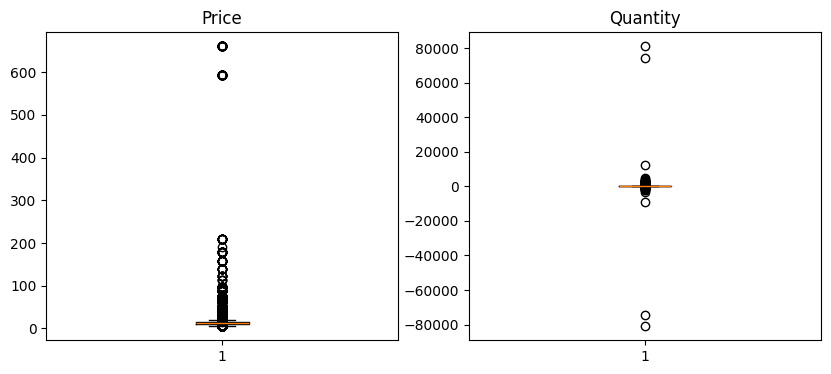

In [ ]:
# Calculamos percentiles para ver qué tan extremos son los máximos
print(df[["Price", "Quantity"]].quantile([0.01, 0.50, 0.99, 0.999, 1.0]))

# Creamos una figura con dos gráficos lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

# Dibujamos un diagrama de caja para Price
ejes[0].boxplot(df["Price"])

# Le ponemos título al primer gráfico
ejes[0].set_title("Price")

# Dibujamos un diagrama de caja para Quantity
ejes[1].boxplot(df["Quantity"])

# Le ponemos título al segundo gráfico
ejes[1].set_title("Quantity")

# Mostramos los gráficos
plt.show()

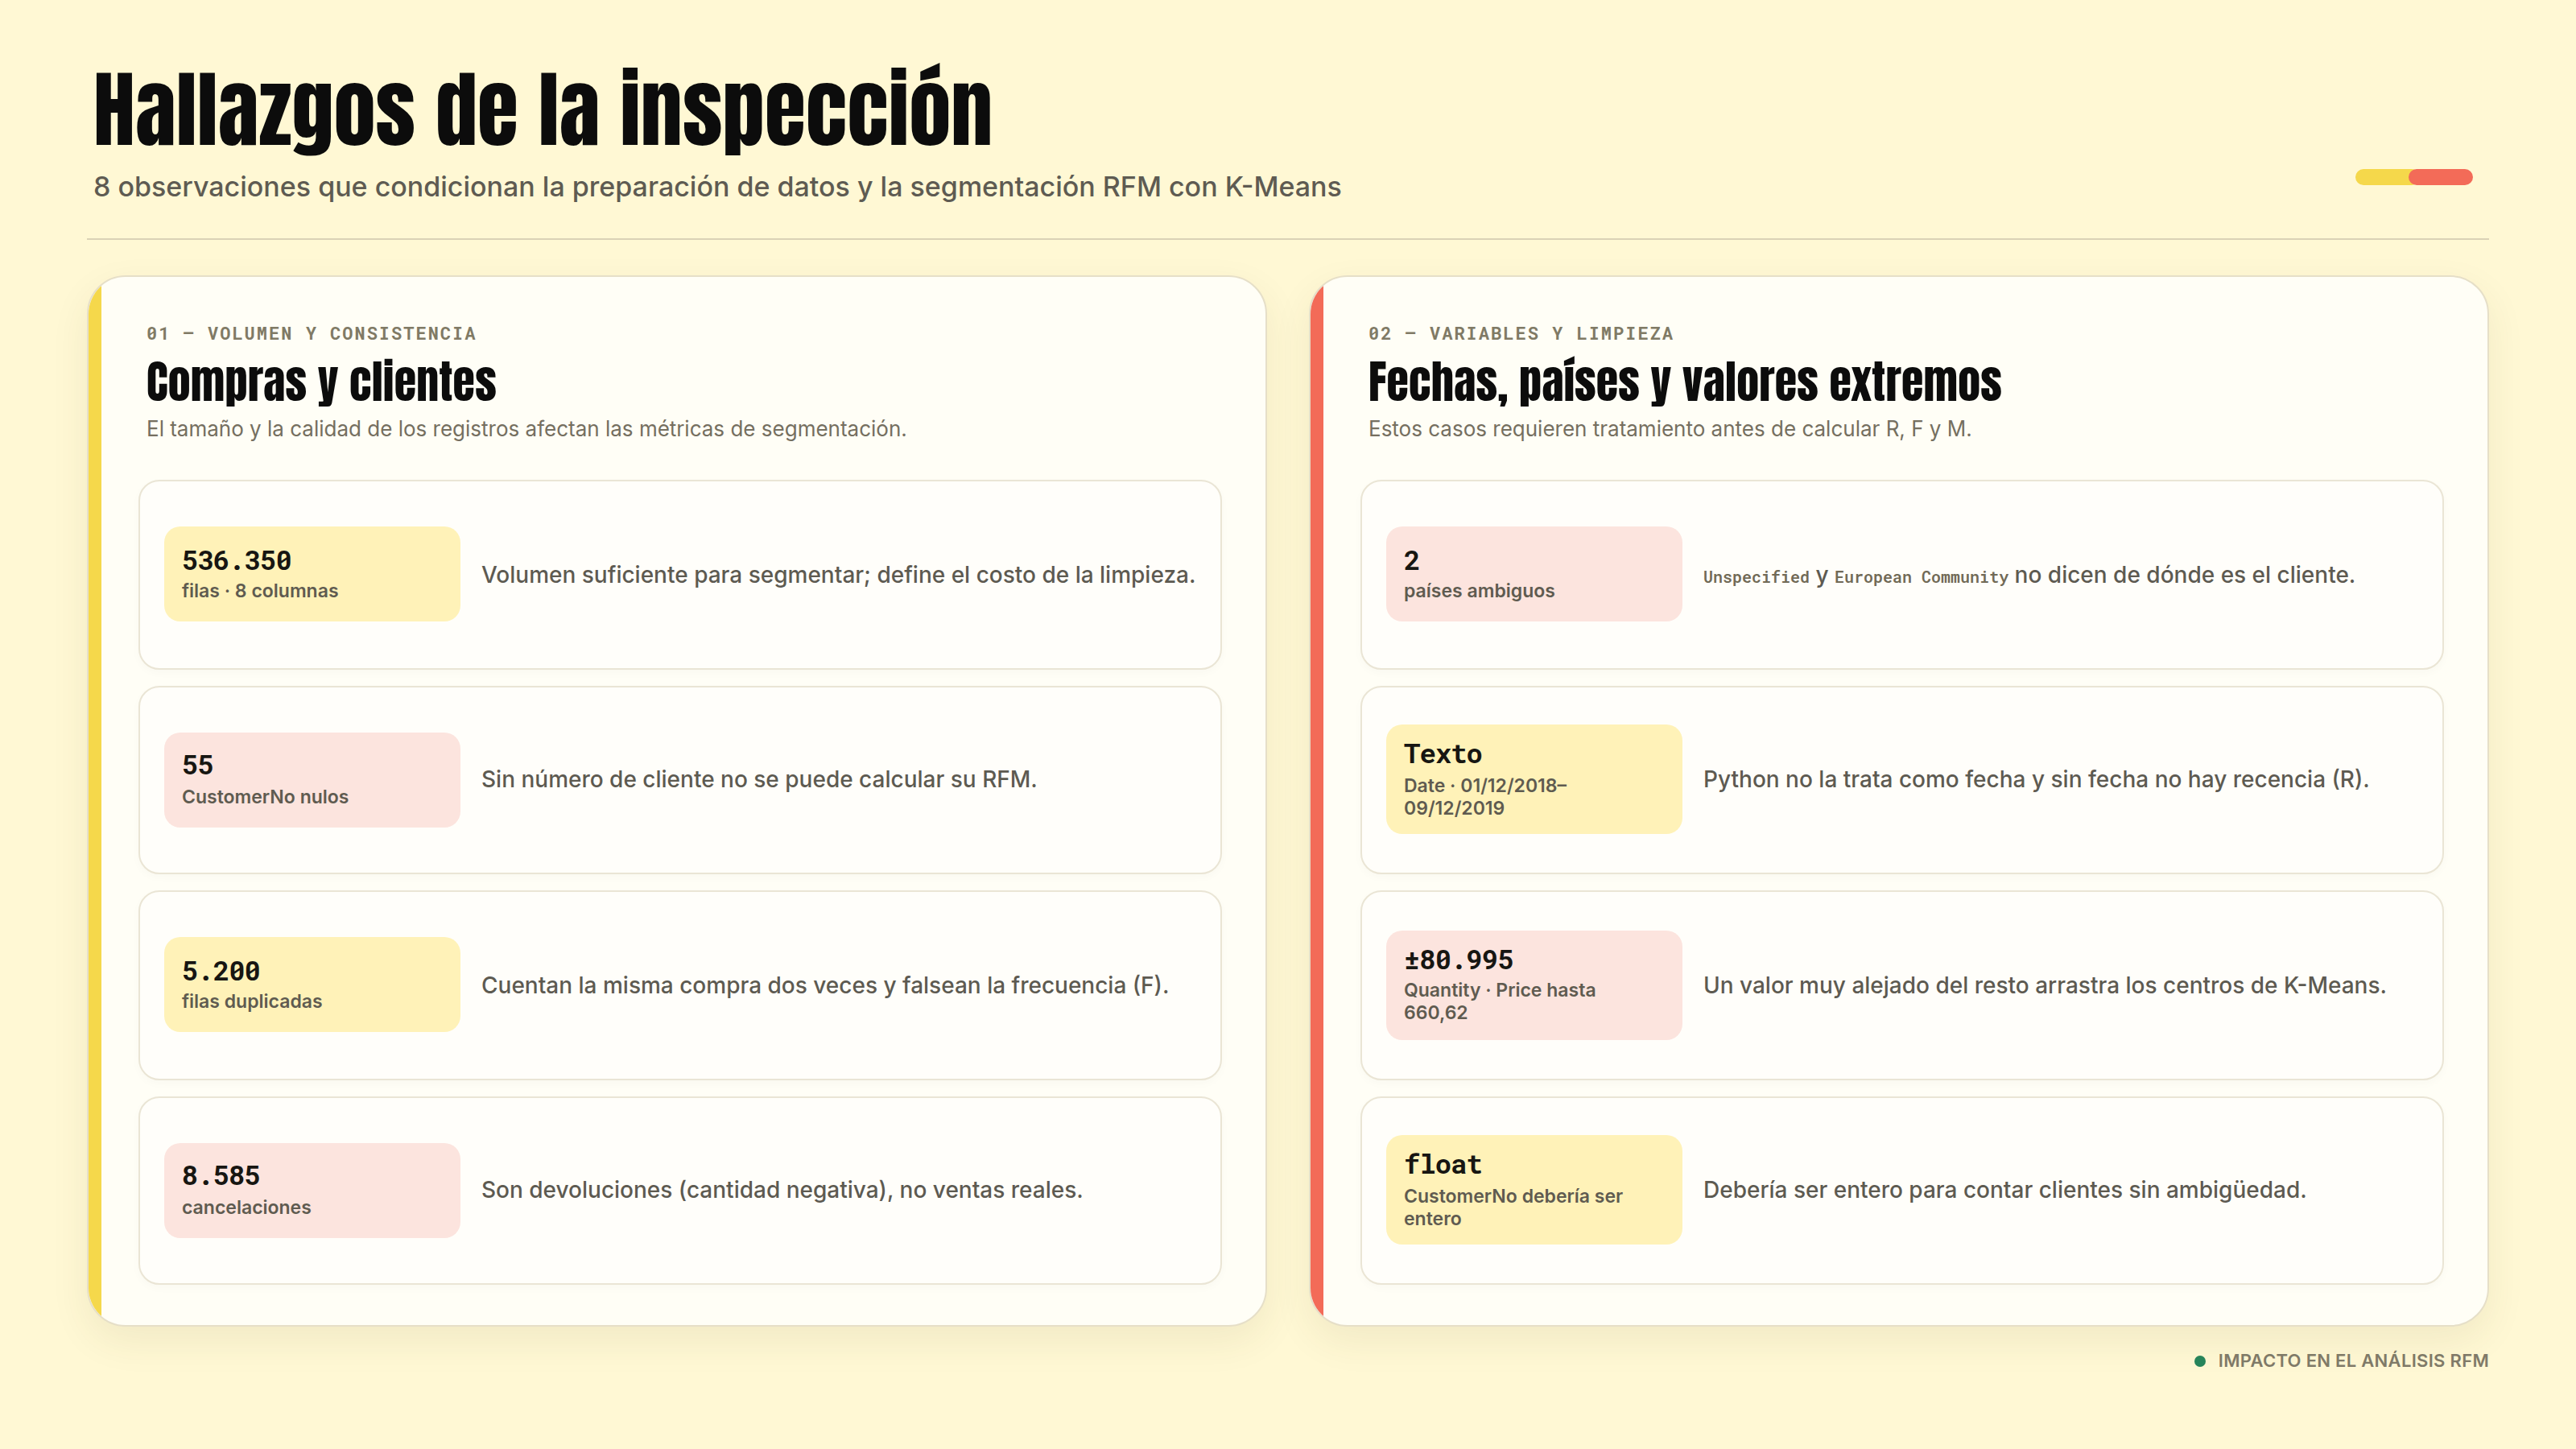

### **3️⃣ Limpieza de datos**
Resolvemos los problemas encontrados uno por uno, siempre sobre una copia (df_limpio) para no perder el original. Después de cada paso mostramos cuántas filas quedan, así sabemos exactamente qué se eliminó.

---

**🎯 Objetivos:**
* 🧽 Eliminar duplicados, nulos y cancelaciones que ensucian el análisis.
* 🌍 Quitar los países ambiguos que no aportan información útil.
* 🚨 Reducir el efecto de los valores extremos sobre los algoritmos.
* 🔧 Dejar cada columna con el tipo de dato adecuado para trabajar.
* ➕ Crear la columna TotalPrice para analizar el gasto de cada compra.

In [ ]:
# Creamos una copia para conservar el dataset original intacto
df_limpio = df.copy()

# Guardamos la cantidad inicial de filas para comparar al final
filas_inicio = len(df_limpio)

In [ ]:
# Eliminamos las filas que están completamente repetidas
df_limpio = df_limpio.drop_duplicates()

# Mostramos cuántas filas quedan
print(f"Tras quitar duplicados: {len(df_limpio)}")

Tras quitar duplicados: 531150


In [ ]:
# Eliminamos las filas donde falta el número de cliente
df_limpio = df_limpio.dropna(subset=["CustomerNo"])

# Mostramos cuántas filas quedan
print(f"Tras quitar clientes nulos: {len(df_limpio)}")

Tras quitar clientes nulos: 531095


In [ ]:
# Nos aseguramos de quedarnos sólo con cantidades positivas
df_limpio = df_limpio[df_limpio["Quantity"] > 0]

# Mostramos cuántas filas quedan
print(f"Tras quitar cantidades negativas: {len(df_limpio)}")

Tras quitar cantidades negativas: 522601


In [ ]:
# Definimos la lista de países que no aportan información
paises_raros = ["Unspecified", "European Community"]

# Eliminamos las filas con esos países
df_limpio = df_limpio[~df_limpio["Country"].isin(paises_raros)]

# Mostramos cuántas filas quedan
print(f"Tras quitar países ambiguos: {len(df_limpio)}")

Tras quitar países ambiguos: 522101


In [ ]:
# Comparamos distintos percentiles de corte ANTES de eliminar los outliers
percentiles = [0.99, 0.995, 0.999, 0.9999]

# Creamos una lista vacía para guardar una fila de resultados por cada percentil
filas_tabla = []

# Repetimos lo siguiente para cada percentil
for p in percentiles:
    # Calculamos el límite superior de Quantity para este percentil
    lim_cantidad = df_limpio["Quantity"].quantile(p)
    # Calculamos el límite superior de Price para este percentil
    lim_precio = df_limpio["Price"].quantile(p)
    # Contamos cuántas filas se eliminarían (las que superan alguno de los dos límites)
    eliminadas = ((df_limpio["Quantity"] > lim_cantidad) | (df_limpio["Price"] > lim_precio)).sum()
    # Guardamos los resultados de este percentil
    filas_tabla.append({
        "Percentil": f"{p * 100:g} %",
        "Corte Quantity": round(lim_cantidad),
        "Corte Price": round(lim_precio, 2),
        "Filas eliminadas": eliminadas,
        "% eliminado": round(eliminadas / len(df_limpio) * 100, 2)
    })

# Mostramos la tabla comparativa
pd.DataFrame(filas_tabla)

,Percentil,Corte Quantity,Corte Price,Filas eliminadas,% eliminado
0,99 %,100,27.30,9158,1.75
1,99.5 %,160,30.71,4978,0.95
2,99.9 %,456,44.37,1024,0.20
3,99.99 %,1437,594.50,83,0.02


In [ ]:
# Calculamos el límite superior de Quantity (percentil 99,9)
limite_cantidad = df_limpio["Quantity"].quantile(0.999)

# Calculamos el límite superior de Price (percentil 99,9)
limite_precio = df_limpio["Price"].quantile(0.999)

# Mostramos los límites para saber desde dónde se elimina
print(f"Límite Quantity: {limite_cantidad} | Límite Price: {limite_precio}")

# Nos quedamos sólo con las filas que no superan ninguno de los límites
df_limpio = df_limpio[(df_limpio["Quantity"] <= limite_cantidad) & (df_limpio["Price"] <= limite_precio)]

# Mostramos cuántas filas quedan
print(f"Tras quitar outliers: {len(df_limpio)}")

Límite Quantity: 456.0 | Límite Price: 44.37
Tras quitar outliers: 521077


**🤔 ¿Por qué el percentil 99,9?**

Un outlier es un valor muy alejado del resto. Para decidir desde dónde es "demasiado extremo" usamos un percentil: el valor por debajo del cual está cierto porcentaje de las filas.

* **✅ Con el 99,9 % logramos el punto justo:** eliminamos apenas el 0,20% de las filas, conservamos el 99,80% de los datos reales y reducimos drásticamente los picos extremos.


| Percentil | Corte `Quantity` | Corte `Price` | Filas eliminadas |
| :--- | :--- | :--- | :--- |
| 99 % | 100 | 27,30 | 9.158 (1,75 %) |
| 99,5 % | 160 | 30,71 | 4.978 (0,95 %) |
| **99,9 % (elegido)** | **456** | **44,37** | **1.024 (0,20 %)** |
| 99,99 % | 1.437 | 594,50 | 83 (0,02 %) |

* **📝 Nota:** en la inspección el percentil 99,9 daba 432 y 45,10; acá da 456 y 44,37 porque se calcula después de quitar duplicados, nulos, cantidades negativas y países ambiguos (el dataset ya cambió).

In [ ]:
# Convertimos la fecha de texto a formato fecha real
df_limpio["Date"] = pd.to_datetime(df_limpio["Date"], format="%m/%d/%Y")

# Convertimos CustomerNo primero a entero (para quitar el .0) y luego a texto
df_limpio["CustomerNo"] = df_limpio["CustomerNo"].astype(int).astype(str)

# Nos aseguramos de que la columna TransactionNo quede como texto
df_limpio["TransactionNo"] = df_limpio["TransactionNo"].astype(str)

# Quitamos espacios sobrantes al inicio y al final del nombre del producto
df_limpio["ProductName"] = df_limpio["ProductName"].str.strip()

# Quitamos espacios sobrantes al inicio y al final del país
df_limpio["Country"] = df_limpio["Country"].str.strip()

# Creamos la columna con el total gastado en cada fila (precio por cantidad)
df_limpio["TotalPrice"] = df_limpio["Price"] * df_limpio["Quantity"]

# Reiniciamos el índice para que vuelva a ser 0, 1, 2, 3...
df_limpio = df_limpio.reset_index(drop=True)

In [ ]:
# Mostramos la estructura final para confirmar los tipos de dato
df_limpio.info()
print()

# Comprobamos que ya no queden nulos
print("Nulos restantes:", df_limpio.isnull().sum().sum())

# Comprobamos que ya no queden duplicados
print("Duplicados restantes:", df_limpio.duplicated().sum())

# Calculamos cuántas filas se eliminaron en total
filas_eliminadas = filas_inicio - len(df_limpio)

# Calculamos el porcentaje que representan sobre el total original
porcentaje_eliminado = filas_eliminadas / filas_inicio * 100

# Mostramos el resumen antes y después
print(f"Filas antes: {filas_inicio} | Filas después: {len(df_limpio)} | Eliminadas: {porcentaje_eliminado:.2f}%")

# Mostramos las primeras filas del dataset limpio
df_limpio.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 521077 entries, 0 to 521076
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   TransactionNo  521077 non-null  object        
 1   Date           521077 non-null  datetime64[ns]
 2   ProductNo      521077 non-null  object        
 3   ProductName    521077 non-null  object        
 4   Price          521077 non-null  float64       
 5   Quantity       521077 non-null  int64         
 6   CustomerNo     521077 non-null  object        
 7   Country        521077 non-null  object        
 8   TotalPrice     521077 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 35.8+ MB

Nulos restantes: 0
Duplicados restantes: 0
Filas antes: 536350 | Filas después: 521077 | Eliminadas: 2.85%


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country,TotalPrice
0,581482,2019-12-09,22485,Set Of 2 Wooden Market Crates,21.47,12,17490,United Kingdom,257.64
1,581475,2019-12-09,22596,Christmas Star Wish List Chalkboard,10.65,36,13069,United Kingdom,383.40
2,581475,2019-12-09,23235,Storage Tin Vintage Leaf,11.53,12,13069,United Kingdom,138.36
3,581475,2019-12-09,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069,United Kingdom,127.80
4,581475,2019-12-09,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069,United Kingdom,71.64


In [ ]:
# Guardamos el dataset limpio en un nuevo CSV (sin la columna de índice)
df_limpio.to_csv("comercio_electronico_limpio.csv", index=False)
print("✅ Archivo guardado: comercio_electronico_limpio.csv")

✅ Archivo guardado: comercio_electronico_limpio.csv


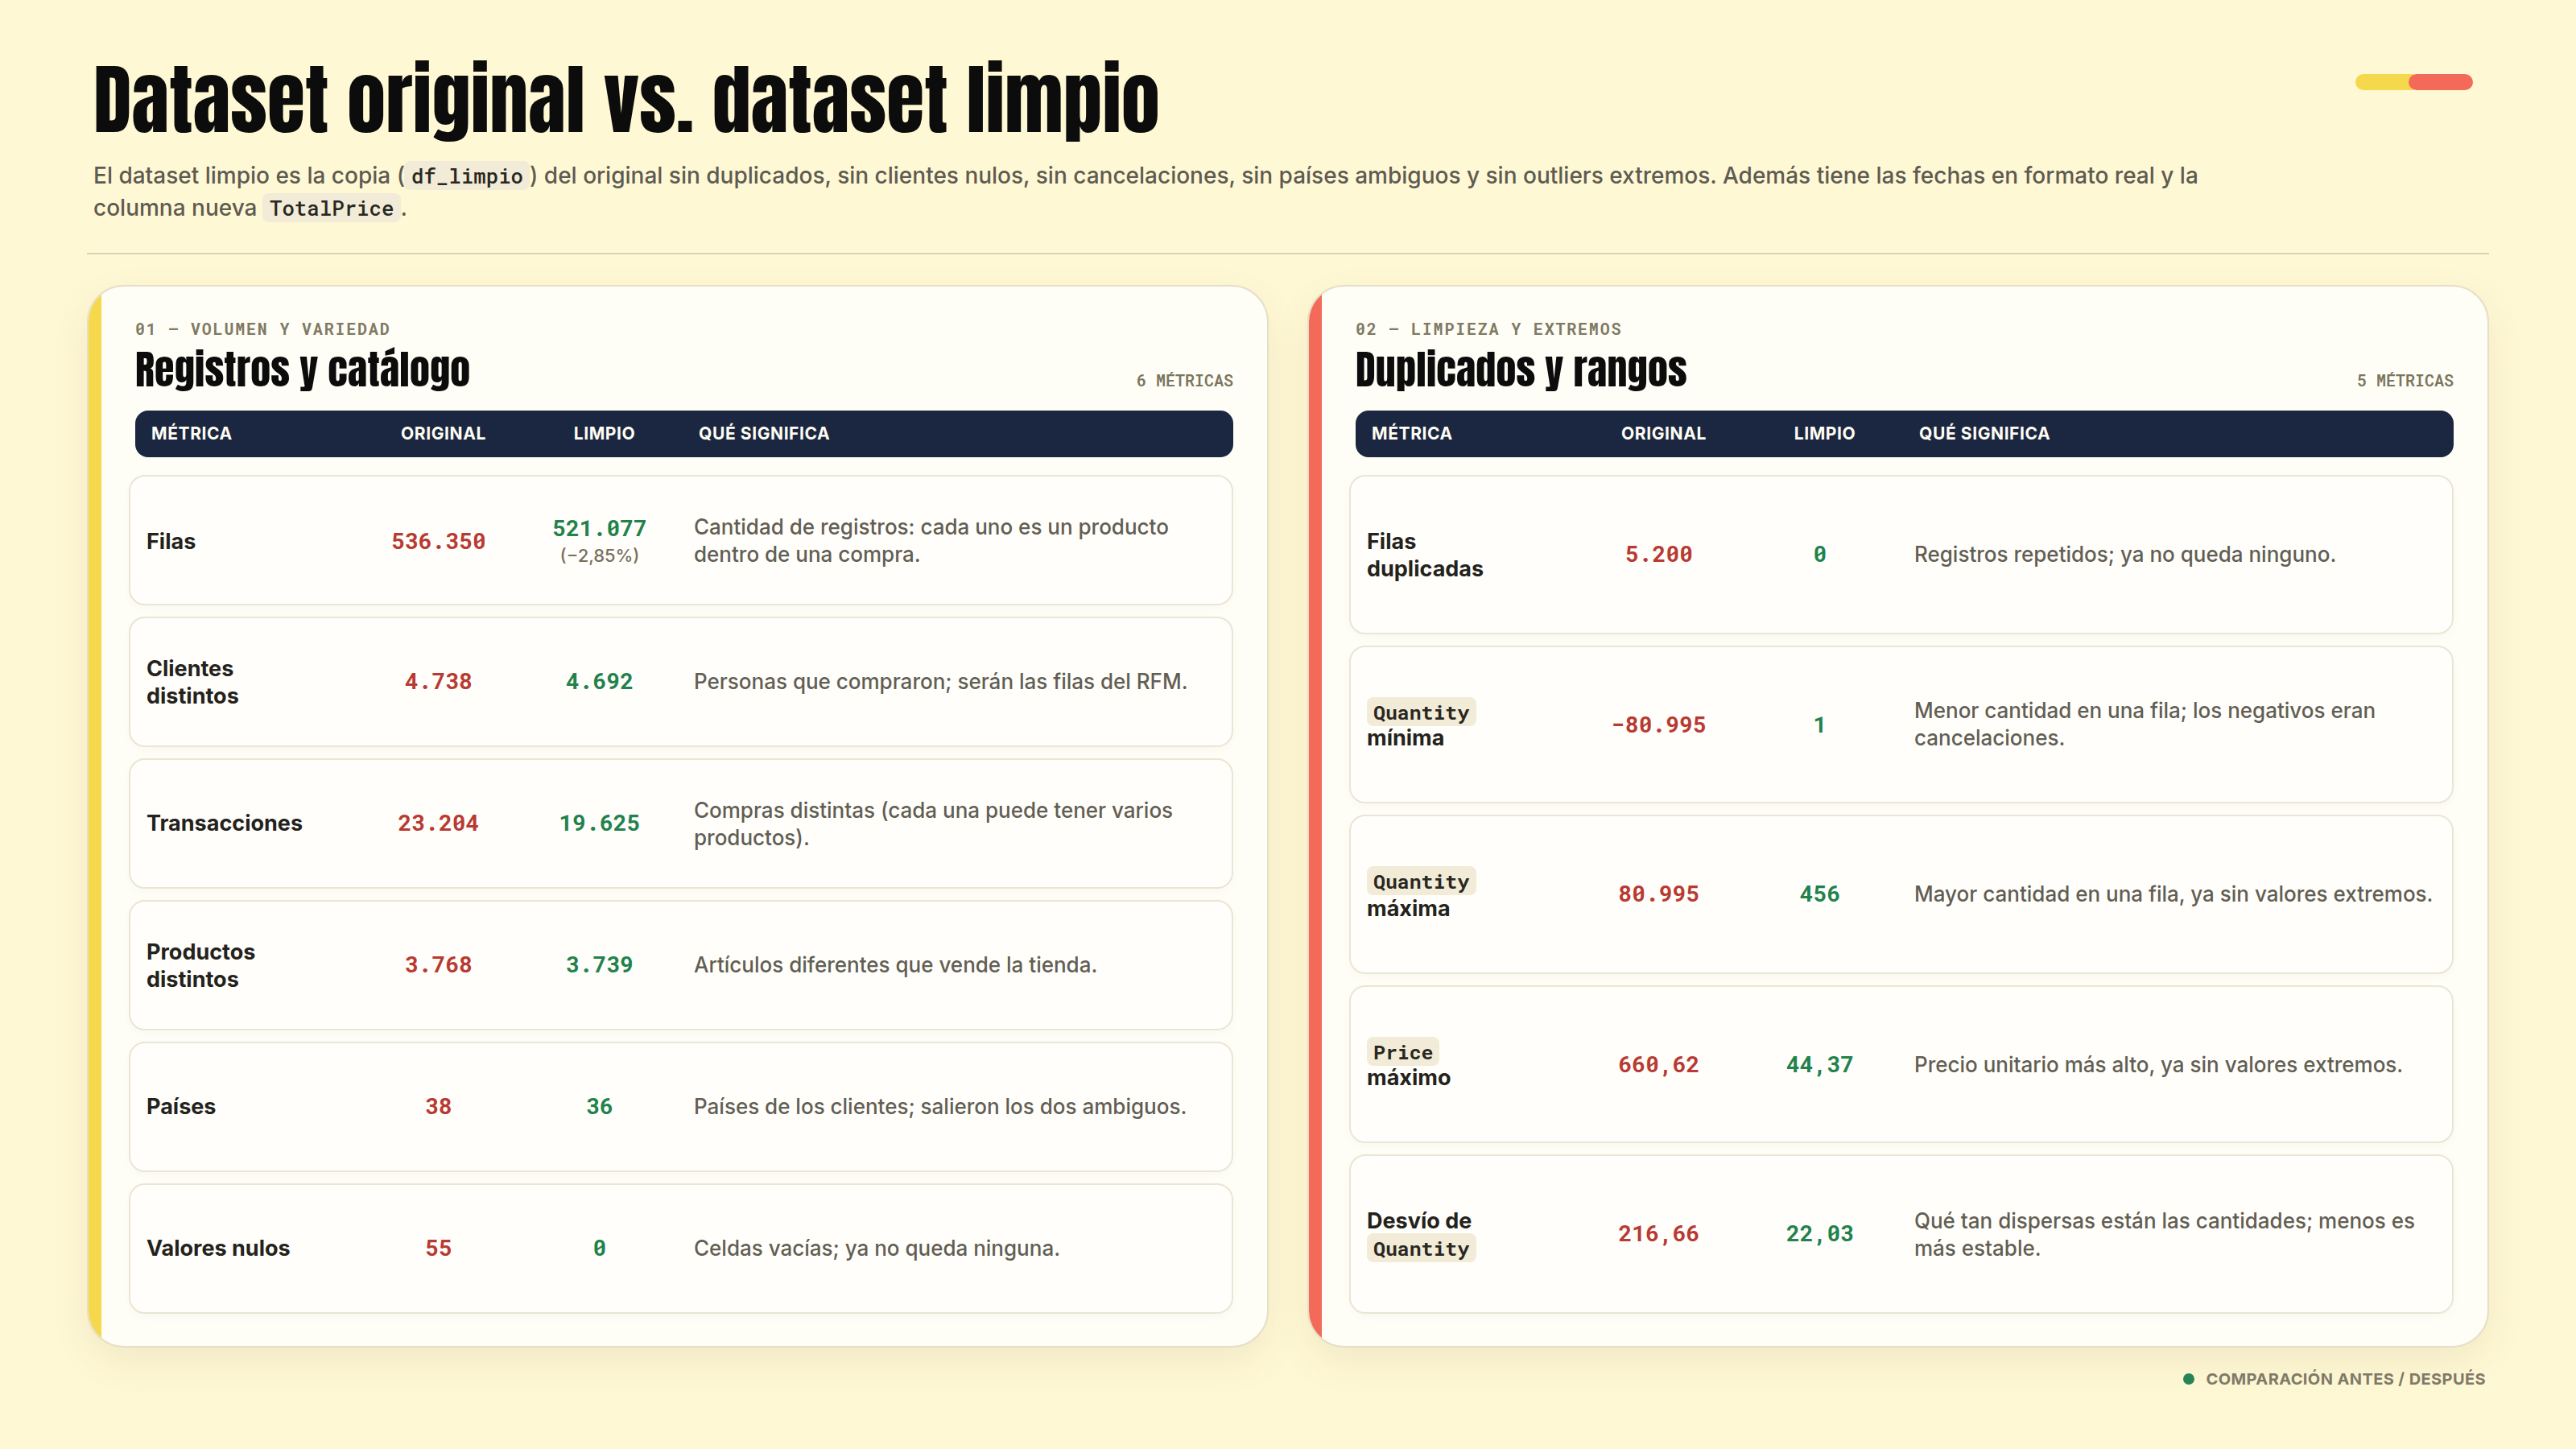

### **4️⃣ Armado del RFM**
Para poder segmentar a nuestros clientes según su comportamiento de compra, primero necesitamos resumir todo su historial individual en tres indicadores clave conocidos como RFM (*Recency, Frequency, Monetary*).

---

**🎯 Objetivo**
Transformar nuestro dataset `df_limpio`, con 521.077 filas de productos, en una nueva tabla `rfm` donde cada fila representa a un cliente único (`CustomerNo`) con sus tres métricas calculadas:

* ⏱️ **R (Recencia):** Días transcurridos desde su última compra hasta el cierre del registro. Menos días es mejor (cliente más activo).
* 🔁 **F (Frecuencia):** Cantidad de transacciones distintas (`TransactionNo`) que realizó. Más compras es mejor.
* 💰 **M (Monetario):** Dinero total gastado (`TotalPrice` acumulado). Más gasto es mejor.




In [ ]:
# Buscamos cuál fue la fecha más reciente de todo el dataset limpio
fecha_maxima = df_limpio["Date"].max()

# Definimos la fecha de referencia sumando 1 día a la fecha máxima (para evitar recencia igual a 0)
fecha_referencia = fecha_maxima + pd.Timedelta(days=1)

# Calculamos RECENCIA (R): buscamos la fecha de última compra de cada cliente
ultima_compra = df_limpio.groupby("CustomerNo")["Date"].max()

# Restamos la última compra de cada cliente a la fecha de referencia y extraemos los días
recencia = (fecha_referencia - ultima_compra).dt.days

# Calculamos FRECUENCIA (F): contamos cuántas transacciones distintas hizo cada cliente
frecuencia = df_limpio.groupby("CustomerNo")["TransactionNo"].nunique()

# Calculamos MONETARIO (M): sumamos todo el dinero gastado (TotalPrice) por cada cliente
monetario = df_limpio.groupby("CustomerNo")["TotalPrice"].sum()

# Armamos la tabla final RFM uniendo los tres resultados en columnas claras
rfm = pd.DataFrame({
    "Recencia": recencia,
    "Frecuencia": frecuencia,
    "Monetario": monetario
})

# Mostramos cuántas filas (clientes) y columnas tiene nuestra tabla RFM
print(f"Clientes totales en RFM: {rfm.shape[0]} | Columnas: {rfm.shape[1]}")

# Mostramos las primeras 5 filas del dataset RFM
rfm.head()

Clientes totales en RFM: 4692 | Columnas: 3


,Recencia,Frecuencia,Monetario
CustomerNo,,,
12004,228,1,1509.60
12006,219,1,24.76
12008,277,1,5689.57
12013,360,1,69.96
12024,177,1,149.52


### **5️⃣ Distribución y preparación de los datos**
K-Means agrupa clientes calculando distancias matemáticas entre ellos. Si una variable tiene valores gigantescos o muy desparejos frente a las demás (por ejemplo, dinero en millones frente a días o cantidad de compras), domina por completo el cálculo y arruina los grupos. Por eso primero miramos cómo se reparten R, F y M, y luego los preparamos.

---

**🎯 Objetivos**
* 👀 **Observar cómo se reparten R, F y M:** comprobar si la mayoría de los clientes se concentra en valores bajos mientras unos pocos tienen valores enormes.
* 📐 **Achicar los valores extremos con logaritmo (`log1p`):** comprimir las colas largas para que esos pocos clientes gigantescos no distorsionen los grupos.
* ⚖️ **Poner R, F y M en la misma escala (`StandardScaler`):** llevar las tres variables a promedio `0` y desvío `1` para que los días, las compras y el dinero pesen exactamente igual en K-Means.
* 🧊 **Explorar los datos listos en 3D:** visualizar cómo queda distribuida la nube de clientes en el espacio antes de buscar los grupos.


       Recencia Frecuencia     Monetario
count  4,692.00   4,692.00      4,692.00
mean      96.95       4.18     11,941.17
std      101.76       7.36     44,955.00
min        1.00       1.00          5.97
25%       19.00       1.00      1,812.07
50%       54.00       2.00      4,704.76
75%      157.00       5.00     11,549.05
max      374.00     207.00  1,969,236.93


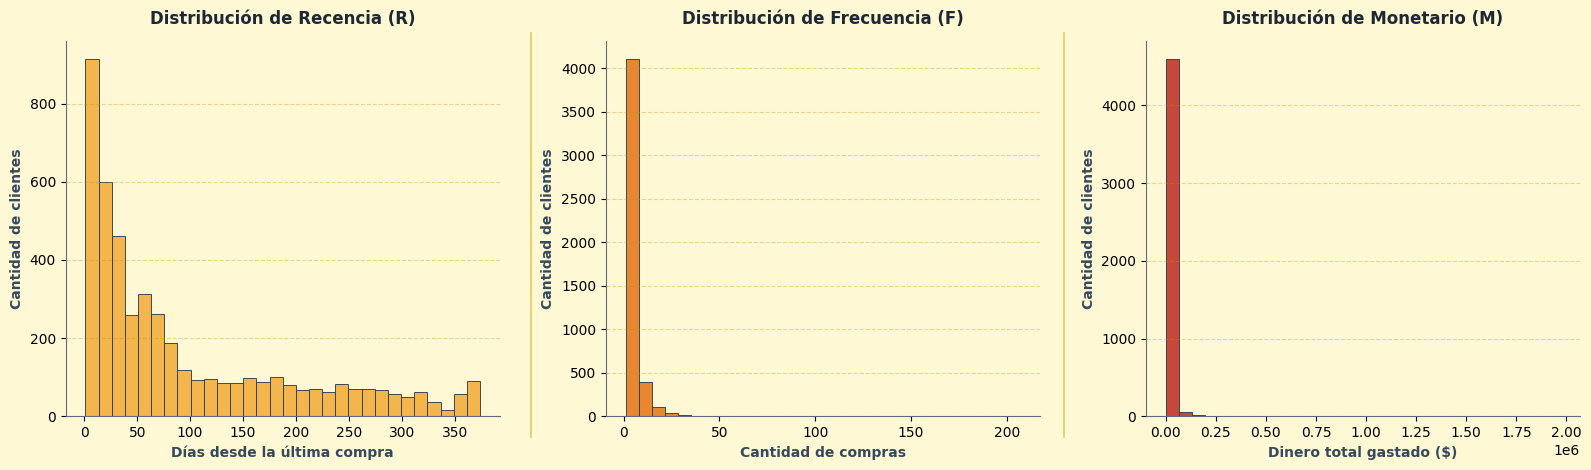

In [ ]:
# Mostramos las estadísticas redondeadas a 2 decimales y sin notación científica
print(rfm.describe().map(lambda x: f"{x:,.2f}"))

# Creamos la figura con 3 gráficos lado a lado y aplicamos el color de fondo crema (#FFF8D4)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor="#FFF8D4")

# Definimos la paleta cálida: amarillo dorado, naranja y rojo intenso
colores = ["#F5B041", "#E67E22", "#C0392B"]
columnas = ["Recencia", "Frecuencia", "Monetario"]
titulos = ["Distribución de Recencia (R)", "Distribución de Frecuencia (F)", "Distribución de Monetario (M)"]
etiquetas_x = ["Días desde la última compra", "Cantidad de compras", "Dinero total gastado ($)"]

# Recorremos los 3 gráficos para aplicarles el diseño personalizado
for i in range(3):
    ax = ejes[i]
    col = columnas[i]

    # Aplicamos el mismo fondo crema dentro del área de cada gráfico
    ax.set_facecolor("#FFF8D4")

    # Dibujamos el histograma con borde oscuro fino para que el amarillo y naranja resalten bien
    ax.hist(rfm[col], bins=30, color=colores[i], edgecolor="#2C3E50", linewidth=0.7, alpha=0.92)

    # Configuramos título en negrita y etiquetas claras en ambos ejes
    ax.set_title(titulos[i], fontsize=12, fontweight="bold", color="#1C2833", pad=12)
    ax.set_xlabel(etiquetas_x[i], fontsize=10, fontweight="bold", color="#34495E")
    ax.set_ylabel("Cantidad de clientes", fontsize=10, fontweight="bold", color="#34495E")

    # Agregamos una grilla horizontal punteada suave en tono tierra/gris cálido
    ax.grid(axis="y", linestyle="--", color="#B7950B", alpha=0.35)

    # Ocultamos los bordes superior y derecho para un acabado moderno
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#5D6D7E")
    ax.spines["bottom"].set_color("#5D6D7E")

# Ajustamos primero los espacios entre los gráficos
plt.tight_layout(w_pad=3.0)

# Agregamos dos líneas divisorias verticales entre los 3 gráficos (en 1/3 y 2/3 del ancho)
linea1 = plt.Line2D([0.335, 0.335], [0.08, 0.92], transform=fig.transFigure, color="#D4AC0D", linestyle="-", linewidth=1.2, alpha=0.6)
linea2 = plt.Line2D([0.668, 0.668], [0.08, 0.92], transform=fig.transFigure, color="#D4AC0D", linestyle="-", linewidth=1.2, alpha=0.6)
fig.add_artist(linea1)
fig.add_artist(linea2)

# Mostramos el resultado final
plt.show()

In [ ]:
# Importamos StandardScaler para poner todas las variables en la misma escala
from sklearn.preprocessing import StandardScaler

# Aplicamos logaritmo (log1p suma 1 antes del logaritmo para evitar errores si hubiera ceros)
rfm_log = np.log1p(rfm)

# Creamos el escalador estándar
escalador = StandardScaler()

# Ajustamos y transformamos los datos con logaritmo para que tengan promedio 0 y desvío 1
rfm_escalado = escalador.fit_transform(rfm_log)

# Convertimos el resultado nuevamente en una tabla (DataFrame) con los mismos nombres de columnas
rfm_escalado = pd.DataFrame(rfm_escalado, index=rfm.index, columns=rfm.columns)

# Mostramos las primeras 5 filas ya transformadas y escaladas para ver cómo quedaron los números
print("Primeras 5 filas listas para K-Means:")
rfm_escalado.head()

Primeras 5 filas listas para K-Means:


,Recencia,Frecuencia,Monetario
CustomerNo,,,
12004,1.165501,-0.969007,-0.711917
12006,1.135013,-0.969007,-3.476864
12008,1.312947,-0.969007,0.188786
12013,1.511614,-0.969007,-2.788728
12024,0.973921,-0.969007,-2.278053


**✅ ¿Qué conseguimos con esta transformación?**

Logramos transformar los números originales (que mezclaban días, cantidad de compras y dinero, con valores de hasta millones) en una tabla equilibrada y lista para K-Means (`rfm_escalado`):

* ⚖️ **Misma escala para las tres variables:** Ahora Recencia, Frecuencia y **Monetario** se mueven alrededor de `0` (con valores positivos para quienes están por encima del promedio y negativos para quienes están por debajo).

* 🛡️ **Sin dominio de valores extremos:** Gracias al logaritmo previo (`log1p`), los clientes con gastos enormes ya no aplastan al resto, evitando que el dinero domine el cálculo de distancias.

* 🤝 **Peso justo en el algoritmo:** A partir de acá, un cambio en la recencia, en la frecuencia o en el gasto tiene exactamente la misma importancia al momento de agrupar clientes.


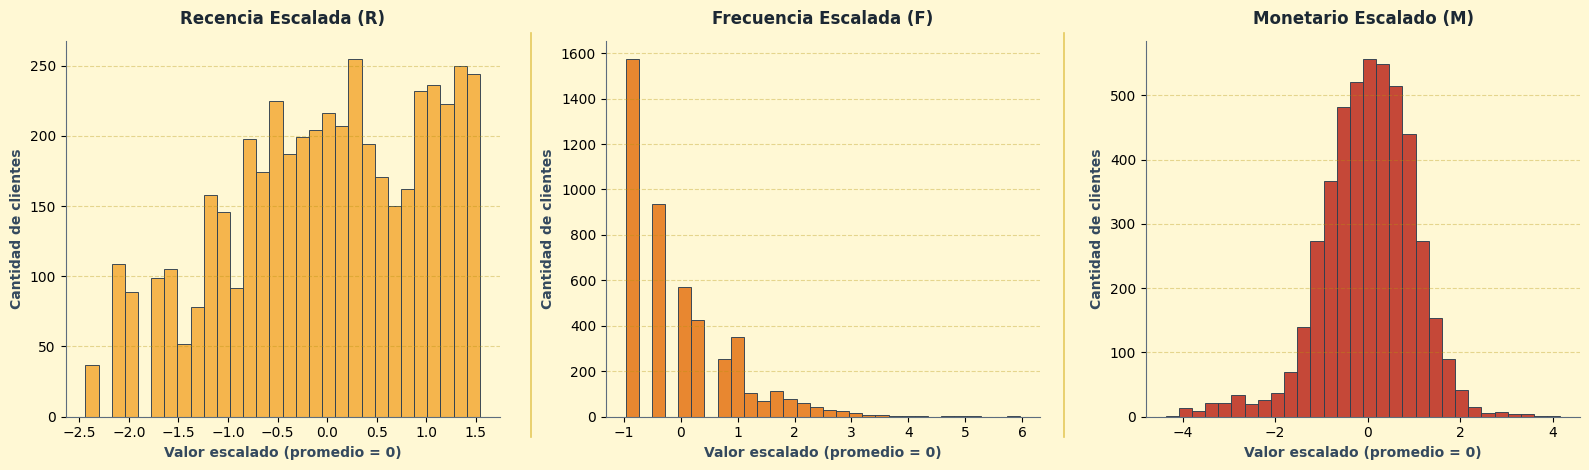

In [ ]:
# Creamos la figura con 3 gráficos lado a lado y aplicamos el fondo crema (#FFF8D4)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor="#FFF8D4")

# Definimos la misma paleta cálida y los nombres de columnas en español
colores = ["#F5B041", "#E67E22", "#C0392B"]
columnas = ["Recencia", "Frecuencia", "Monetario"]
titulos = ["Recencia Escalada (R)", "Frecuencia Escalada (F)", "Monetario Escalado (M)"]
etiquetas_x = ["Valor escalado (promedio = 0)", "Valor escalado (promedio = 0)", "Valor escalado (promedio = 0)"]

# Recorremos los 3 gráficos para aplicarles el diseño personalizado
for i in range(3):
    ax = ejes[i]
    col = columnas[i]

    # Aplicamos el mismo fondo crema dentro de cada gráfico
    ax.set_facecolor("#FFF8D4")

    # Dibujamos el histograma de los datos ya transformados y escalados
    ax.hist(rfm_escalado[col], bins=30, color=colores[i], edgecolor="#2C3E50", linewidth=0.7, alpha=0.92)

    # Configuramos título en negrita y etiquetas claras en ambos ejes
    ax.set_title(titulos[i], fontsize=12, fontweight="bold", color="#1C2833", pad=12)
    ax.set_xlabel(etiquetas_x[i], fontsize=10, fontweight="bold", color="#34495E")
    ax.set_ylabel("Cantidad de clientes", fontsize=10, fontweight="bold", color="#34495E")

    # Agregamos una grilla horizontal punteada suave
    ax.grid(axis="y", linestyle="--", color="#B7950B", alpha=0.35)

    # Ocultamos los bordes superior y derecho para un acabado limpio
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#5D6D7E")
    ax.spines["bottom"].set_color("#5D6D7E")

# Ajustamos primero los espacios entre los gráficos
plt.tight_layout(w_pad=3.0)

# Agregamos las dos líneas divisorias verticales entre los 3 gráficos
linea1 = plt.Line2D([0.335, 0.335], [0.08, 0.92], transform=fig.transFigure, color="#D4AC0D", linestyle="-", linewidth=1.2, alpha=0.6)
linea2 = plt.Line2D([0.668, 0.668], [0.08, 0.92], transform=fig.transFigure, color="#D4AC0D", linestyle="-", linewidth=1.2, alpha=0.6)
fig.add_artist(linea1)
fig.add_artist(linea2)

# Mostramos los gráficos finales
plt.show()

### **6️⃣ Comparativa al escalar y cómo seguimos con K-Means**
Todo el proceso matemático de transformación que acabamos de aplicar se traduce directamente en cómo se organizan nuestros clientes en el espacio. Para comprobar el impacto real antes de agrupar, enfrentamos cara a cara los dos escenarios con los mismos clientes:

* 📦 **Cubo 1 — Datos Originales (Sin escalar):** Muestra la distribución cruda de **Recencia**, **Frecuencia** y **Monetario**, donde las diferencias de magnitud entre variables son extremas.
* ✨ **Cubo 2 — Datos Listos (`Logaritmo + StandardScaler`):** Muestra el mismo grupo de clientes pero con sus valores comprimidos y estandarizados, dejando el terreno equilibrado.
* 🎯 **¿Qué buscamos ver?:** Comprobar visualmente cómo pasamos de una nube distorsionada a un espacio justo donde K-Means pueda medir distancias sin sesgos.


In [ ]:
# 1. Elegimos los mismos 1000 clientes al azar para comparar exactamente los mismos puntos en ambos cubos
muestra_ids = rfm.sample(1000, random_state=42).index
crudo = rfm.loc[muestra_ids]
escalado = rfm_escalado.loc[muestra_ids]

# 2. Creamos la figura con 2 espacios 3D lado a lado
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    horizontal_spacing=0.04,
    subplot_titles=("<b>1. Sin Escalar (Datos Originales)</b>", "<b>2. Escalado (Log + StandardScaler)</b>")
)

# Definimos el estilo de las esferas (con borde oscuro y degradado cálido YlOrRd)
estilo_puntos = dict(
    size=4.5, opacity=0.85, color=escalado["Monetario"], colorscale="YlOrRd",
    line=dict(width=0.5, color="#2C3E50")
)

# 3. Cubo izquierdo: datos crudos (se ven todos aplastados en un rincón por los millones de Monetario)
fig.add_trace(go.Scatter3d(
    x=crudo["Recencia"], y=crudo["Frecuencia"], z=crudo["Monetario"],
    mode="markers", marker=estilo_puntos, showlegend=False
), row=1, col=1)

# 4. Cubo derecho: datos listos (se despliegan en una nube pareja) + barra de color a la derecha
fig.add_trace(go.Scatter3d(
    x=escalado["Recencia"], y=escalado["Frecuencia"], z=escalado["Monetario"],
    mode="markers", showlegend=False,
    marker=dict(**estilo_puntos, colorbar=dict(title="<b>Monetario<br>(Nivel)</b>", thickness=15, len=0.65))
), row=1, col=2)

# 5. Aplicamos las mismas paredes cálidas (#F9E79F, #FDEBD0, #FADBD8) y cámara a ambos cubos
paredes_3d = dict(
    xaxis=dict(title="<b>Recencia (R)</b>", backgroundcolor="#F9E79F", gridcolor="white", showbackground=True),
    yaxis=dict(title="<b>Frecuencia (F)</b>", backgroundcolor="#FDEBD0", gridcolor="white", showbackground=True),
    zaxis=dict(title="<b>Monetario (M)</b>", backgroundcolor="#FADBD8", gridcolor="white", showbackground=True),
    camera=dict(eye=dict(x=1.55, y=1.55, z=1.15))
)

fig.update_layout(
    title=dict(text="<b>Comparativa 3D: Impacto de Preparar los Datos para K-Means</b>", x=0.02, y=0.96, font=dict(size=17)),
    width=1050, height=580, paper_bgcolor="#FFF8D4",
    font=dict(family="Arial, sans-serif", color="#1C2833"),
    margin=dict(l=10, r=10, t=75, b=10),
    scene=paredes_3d,
    scene2=paredes_3d
)

fig.show()

**⚙️ ¿Cómo funciona K-Means?**

Como acabamos de comprobar en la comparativa, los datos ya están nivelados y listos en el espacio para medir distancias justas entre clientes. A partir de aquí entra en acción K-Means, un algoritmo de aprendizaje no supervisado que segmenta a nuestros clientes por cercanía matemática sin etiquetas previas.

---

**🗺️ ¿Cómo seguimos?**
* 🎯 **Elegir k:** Compararemos candidatos entre `2` y `6` usando el **Método del Codo** y el **Puntaje de Silueta** para descubrir cuántos grupos conviene formar.

* 📍 **Entrenar e interpretar:** Una vez definido `k`, ubicaremos los centros iniciales, asignaremos cada cliente al más cercano y los ajustaremos iterativamente hasta converger y analizar cada segmento.

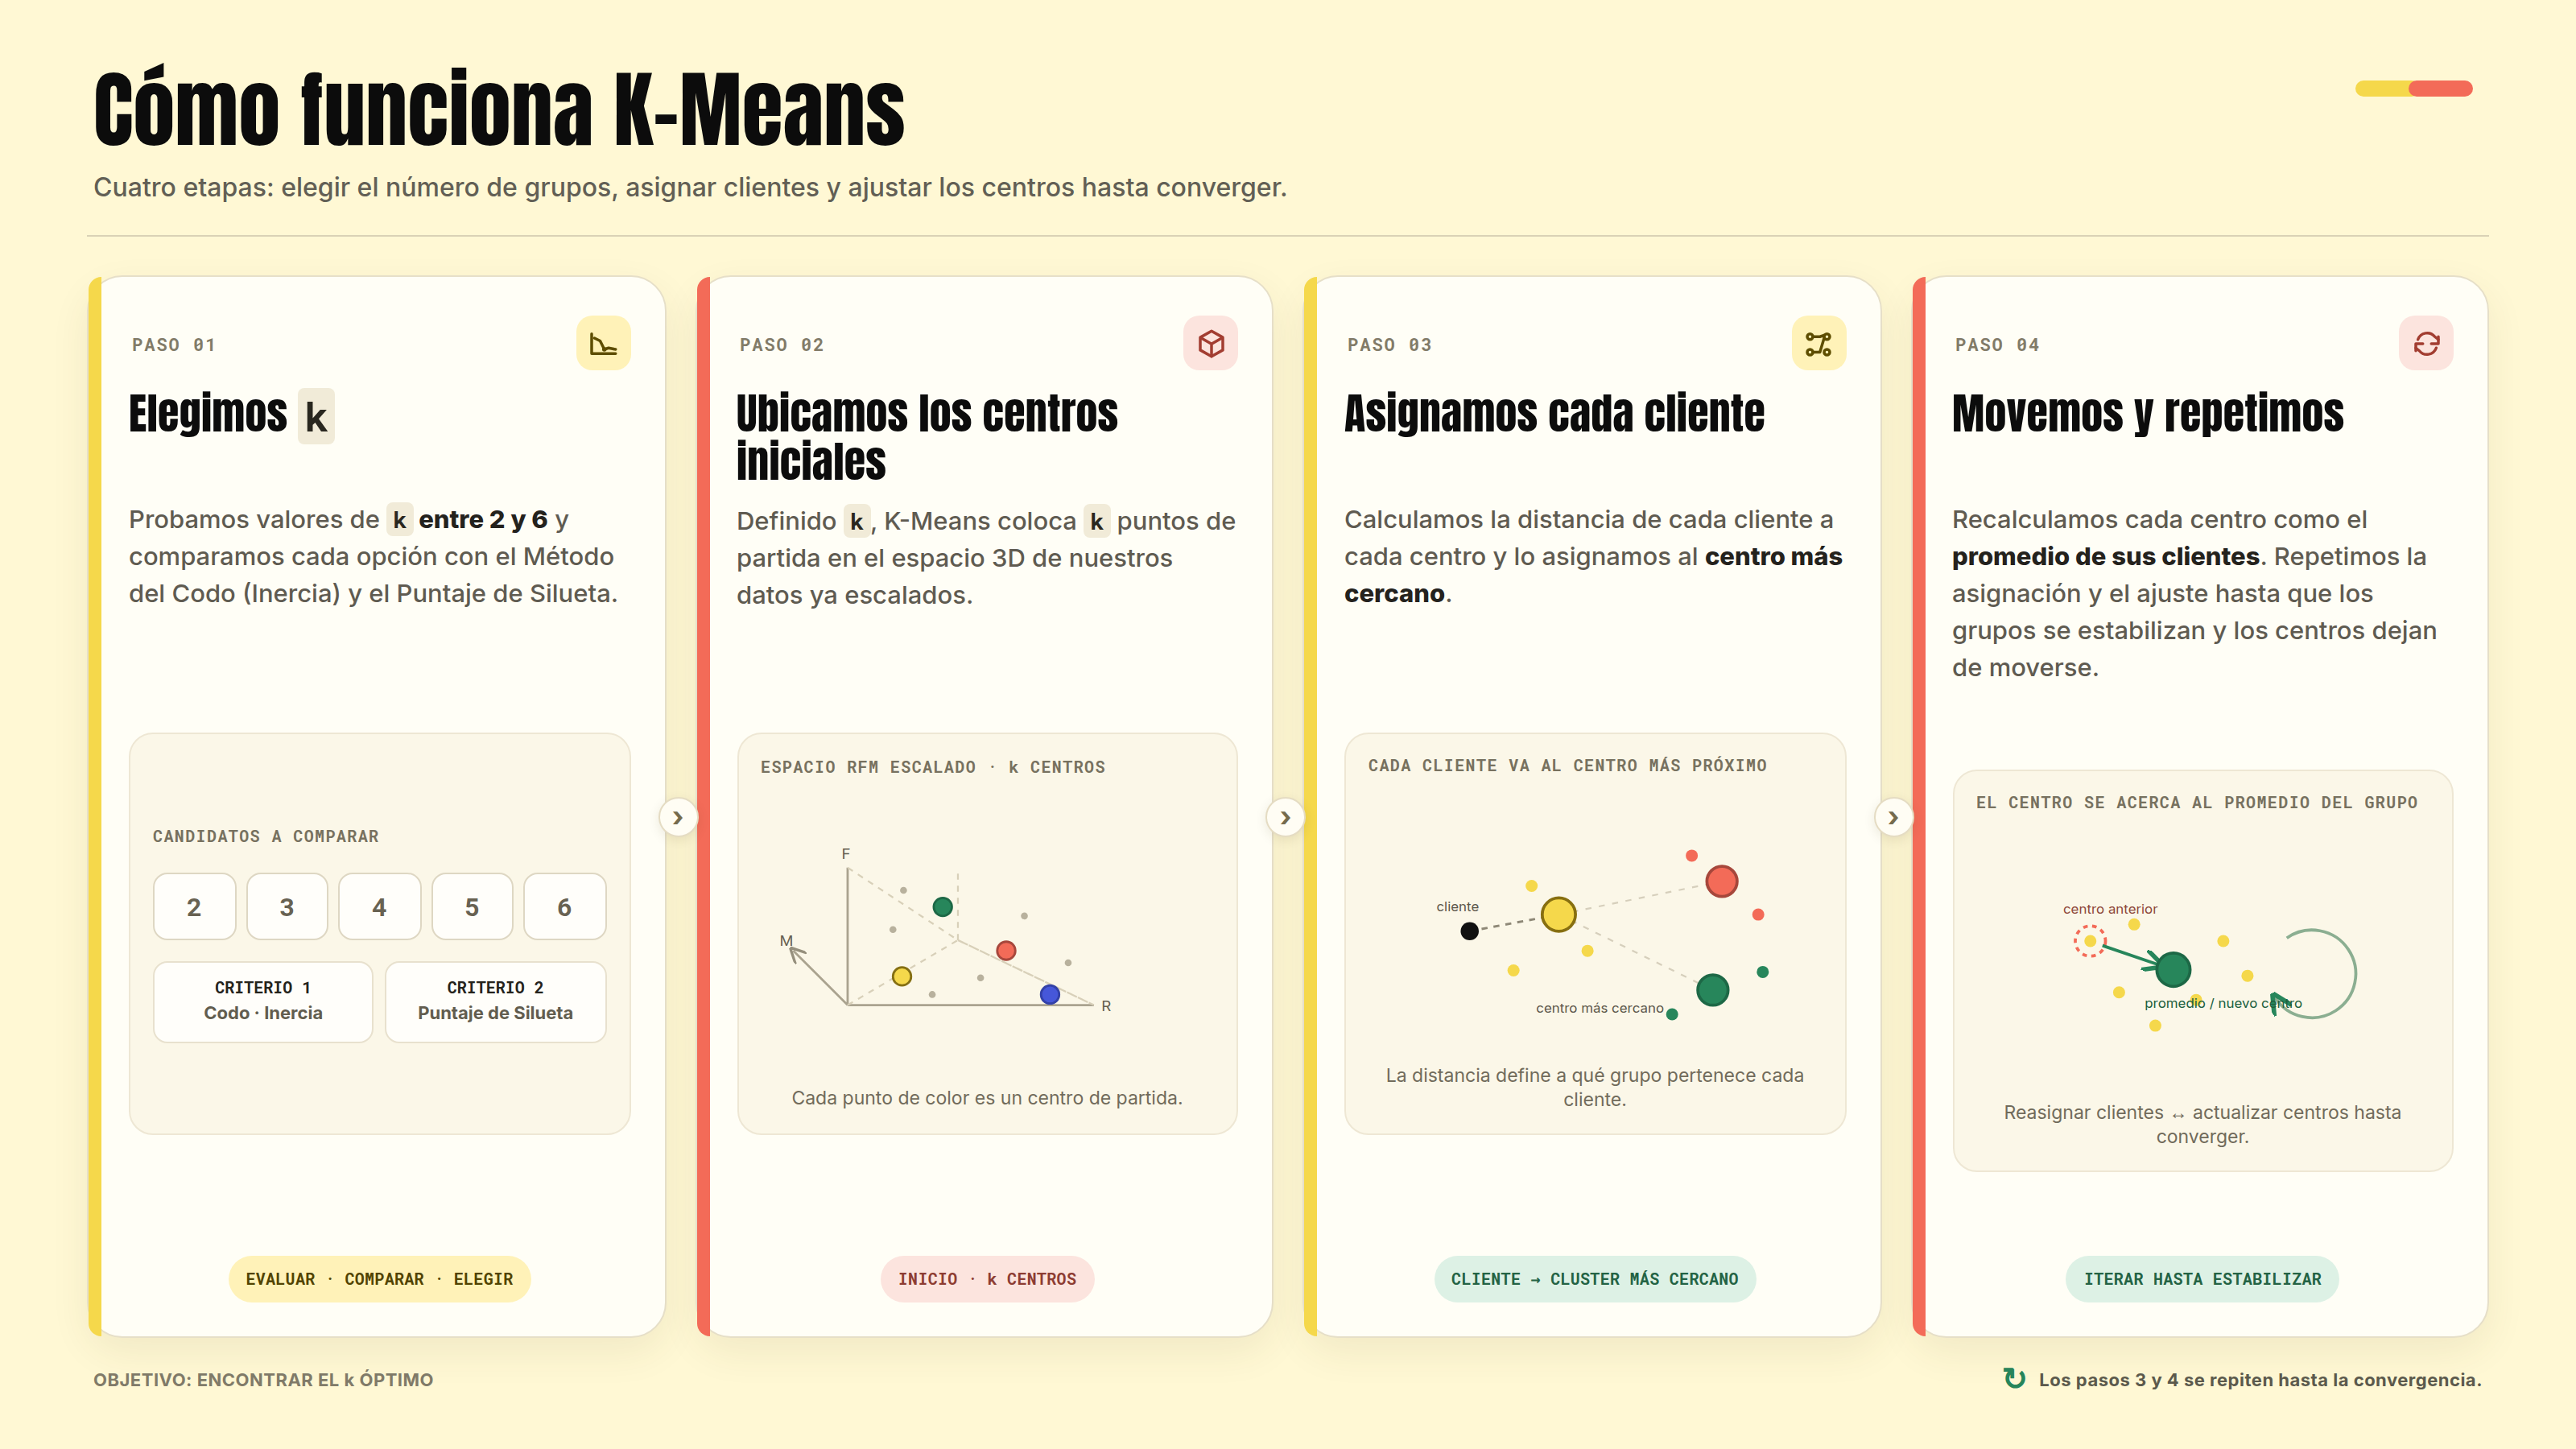

### **7️⃣ Elegir la cantidad de grupos (k)**
K-Means necesita que le digamos de antemano cuántos grupos formar. Como no existe una única respuesta automática, probamos distintos valores de `k` (de 2 a 6) y los comparamos con dos herramientas matemáticas para tomar una decisión fundamentada.

* 📈 **Método del Codo (Inercia):** ver a partir de qué `k` agregar más grupos casi no mejora la compactación.
* 📐 **Puntaje de Silueta:** medir qué tan bien separados y definidos quedan los grupos entre sí.
* 🧩 **Decidir un `k` óptimo:** elegir una cantidad de segmentos que sea estadísticamente sólida y útil para el negocio.

---

**📖 Cómo leer las herramientas**
* 📉 **Inercia (Codo):** mide qué tan apretados están los clientes dentro de su grupo (menor es más compacto). Siempre baja al aumentar `k`; buscamos el quiebre ("codo") donde la curva deja de caer bruscamente y empieza a aplanarse.
* 📏 **Silueta:** va de `-1` a `1`. Cuanto más cerca de `1`, mejor separados están los grupos entre sí y menos se superponen.


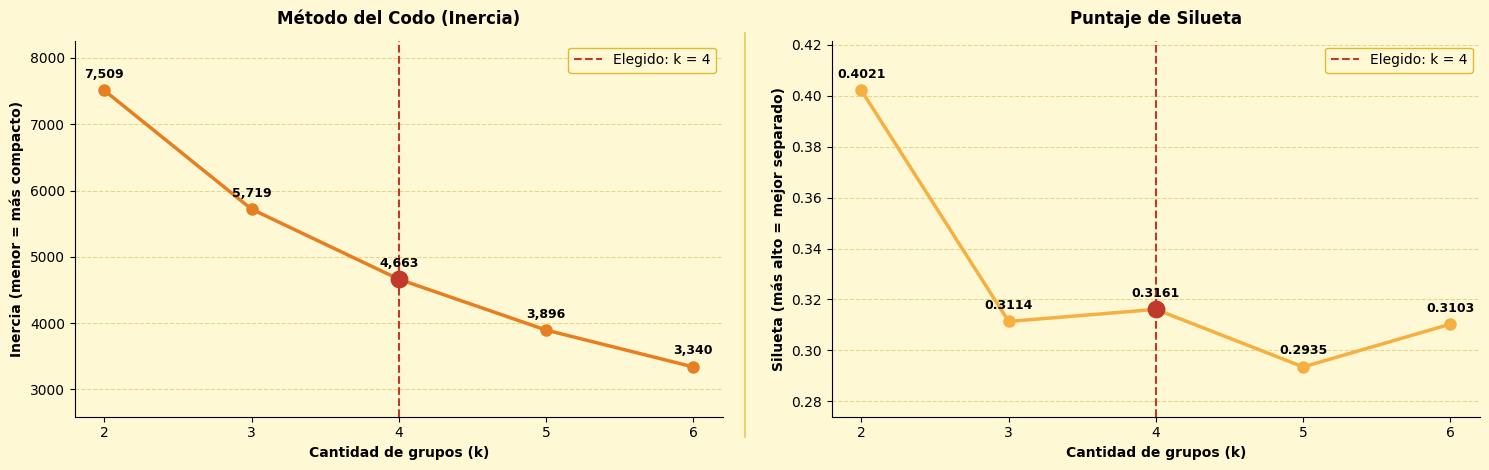

In [ ]:
# Importamos KMeans y la métrica de silueta
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Listas vacías para guardar los resultados de k = 2 a 6
inercias, siluetas = [], []
valores_k = [2, 3, 4, 5, 6]

# Probamos cada valor de k y guardamos sus métricas
for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(rfm_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(rfm_escalado, etiquetas))

# Creamos la figura con fondo crema (#FFF8D4) y 2 gráficos lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8), facecolor="#FFF8D4")

# Preparamos los datos y textos de cada gráfico para aplicarlos en un bucle
datos = [inercias, siluetas]
colores = ["#E67E22", "#F5B041"]
titulos = ["Método del Codo (Inercia)", "Puntaje de Silueta"]
etiquetas_y = ["Inercia (menor = más compacto)", "Silueta (más alto = mejor separado)"]
formatos = ["{:,.0f}", "{:.4f}"]

# Recorremos ambos gráficos (0 y 1) para darles el mismo estilo profesional
for i in range(2):
    ax = ejes[i]
    ax.set_facecolor("#FFF8D4")

    # Dibujamos la curva principal y resaltamos k = 4 con línea y punto rojo
    ax.plot(valores_k, datos[i], marker="o", markersize=8, color=colores[i], linewidth=2.5)
    ax.axvline(4, color="#C0392B", linestyle="--", linewidth=1.5, label="Elegido: k = 4")
    ax.scatter([4], [datos[i][2]], color="#C0392B", s=140, zorder=4)

    # Escribimos el valor exacto encima de cada punto
    for k, val in zip(valores_k, datos[i]):
        ax.annotate(formatos[i].format(val), (k, val), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, fontweight="bold")

    # Configuramos títulos, ejes, grilla y bordes limpios
    ax.set_title(titulos[i], fontsize=12, fontweight="bold", pad=12)
    ax.set_xlabel("Cantidad de grupos (k)", fontsize=10, fontweight="bold")
    ax.set_ylabel(etiquetas_y[i], fontsize=10, fontweight="bold")
    ax.set_xticks(valores_k)
    ax.margins(y=0.18) # Damos espacio arriba para que no se corten los números
    ax.grid(axis="y", linestyle="--", color="#B7950B", alpha=0.35)
    ax.legend(facecolor="#FFF8D4", edgecolor="#D4AC0D")
    ax.spines[["top", "right"]].set_visible(False)

# Ajustamos márgenes, agregamos la línea divisoria central y mostramos
plt.tight_layout(w_pad=3.5)
fig.add_artist(plt.Line2D([0.50, 0.50], [0.08, 0.92], transform=fig.transFigure, color="#D4AC0D", linewidth=1.2, alpha=0.6))
plt.show()

**Más métricas para elegir k**

La inercia y la silueta no alcanzan solas. Sumamos dos índices más y comprobamos **estabilidad**:

* 📉 **Davies-Bouldin:** mide qué tan parecidos son los grupos entre sí. **Menor es mejor.**

* 📈 **Calinski-Harabasz:** relación entre dispersión entre grupos y dentro de cada grupo. **Mayor es mejor.**

* 🔁 **Estabilidad (ARI):** entrenamos con distintas semillas y comparamos si los grupos se mantienen. **Cerca de 1 = estable.**

In [ ]:
# Importamos las métricas adicionales
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# Creamos una lista vacía para guardar una fila de resultados por cada k
filas = []

# Repetimos lo siguiente para cada valor de k (i es la posición y k el valor)
for i, k in enumerate(valores_k):
    # Entrenamos el modelo con la semilla principal (42) y obtenemos los grupos
    etiquetas_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(rfm_escalado)

    # Lista vacía para guardar qué tan parecidos son los grupos al cambiar la semilla
    aris = []
    # Probamos con otras 4 semillas distintas
    for semilla in [1, 7, 21, 99]:
        # Entrenamos de nuevo con otra semilla
        otras_etiquetas = KMeans(n_clusters=k, random_state=semilla, n_init=10).fit_predict(rfm_escalado)
        # Comparamos ambos resultados (ARI cerca de 1 = los grupos casi no cambian)
        aris.append(adjusted_rand_score(etiquetas_k, otras_etiquetas))

    # Guardamos todas las métricas de este k en una fila
    filas.append({
        "k": k,
        "Inercia": inercias[i],
        "Silueta": siluetas[i],
        "Davies-Bouldin": davies_bouldin_score(rfm_escalado, etiquetas_k),
        "Calinski-Harabasz": calinski_harabasz_score(rfm_escalado, etiquetas_k),
        "Estabilidad (ARI)": np.mean(aris)
    })

# Armamos la tabla final con k como índice y redondeamos a 3 decimales
tabla_metricas = pd.DataFrame(filas).set_index("k").round(3)

# Mostramos la tabla
tabla_metricas


,Inercia,Silueta,Davies-Bouldin,Calinski-Harabasz,Estabilidad (ARI)
k,,,,,
2,7509.418,0.402,0.943,4101.170,0.998
3,5719.140,0.311,1.100,3425.826,0.984
4,4662.630,0.316,1.030,3154.959,0.977
5,3896.089,0.294,1.030,3061.658,0.940
6,3339.832,0.310,0.964,3012.771,0.986


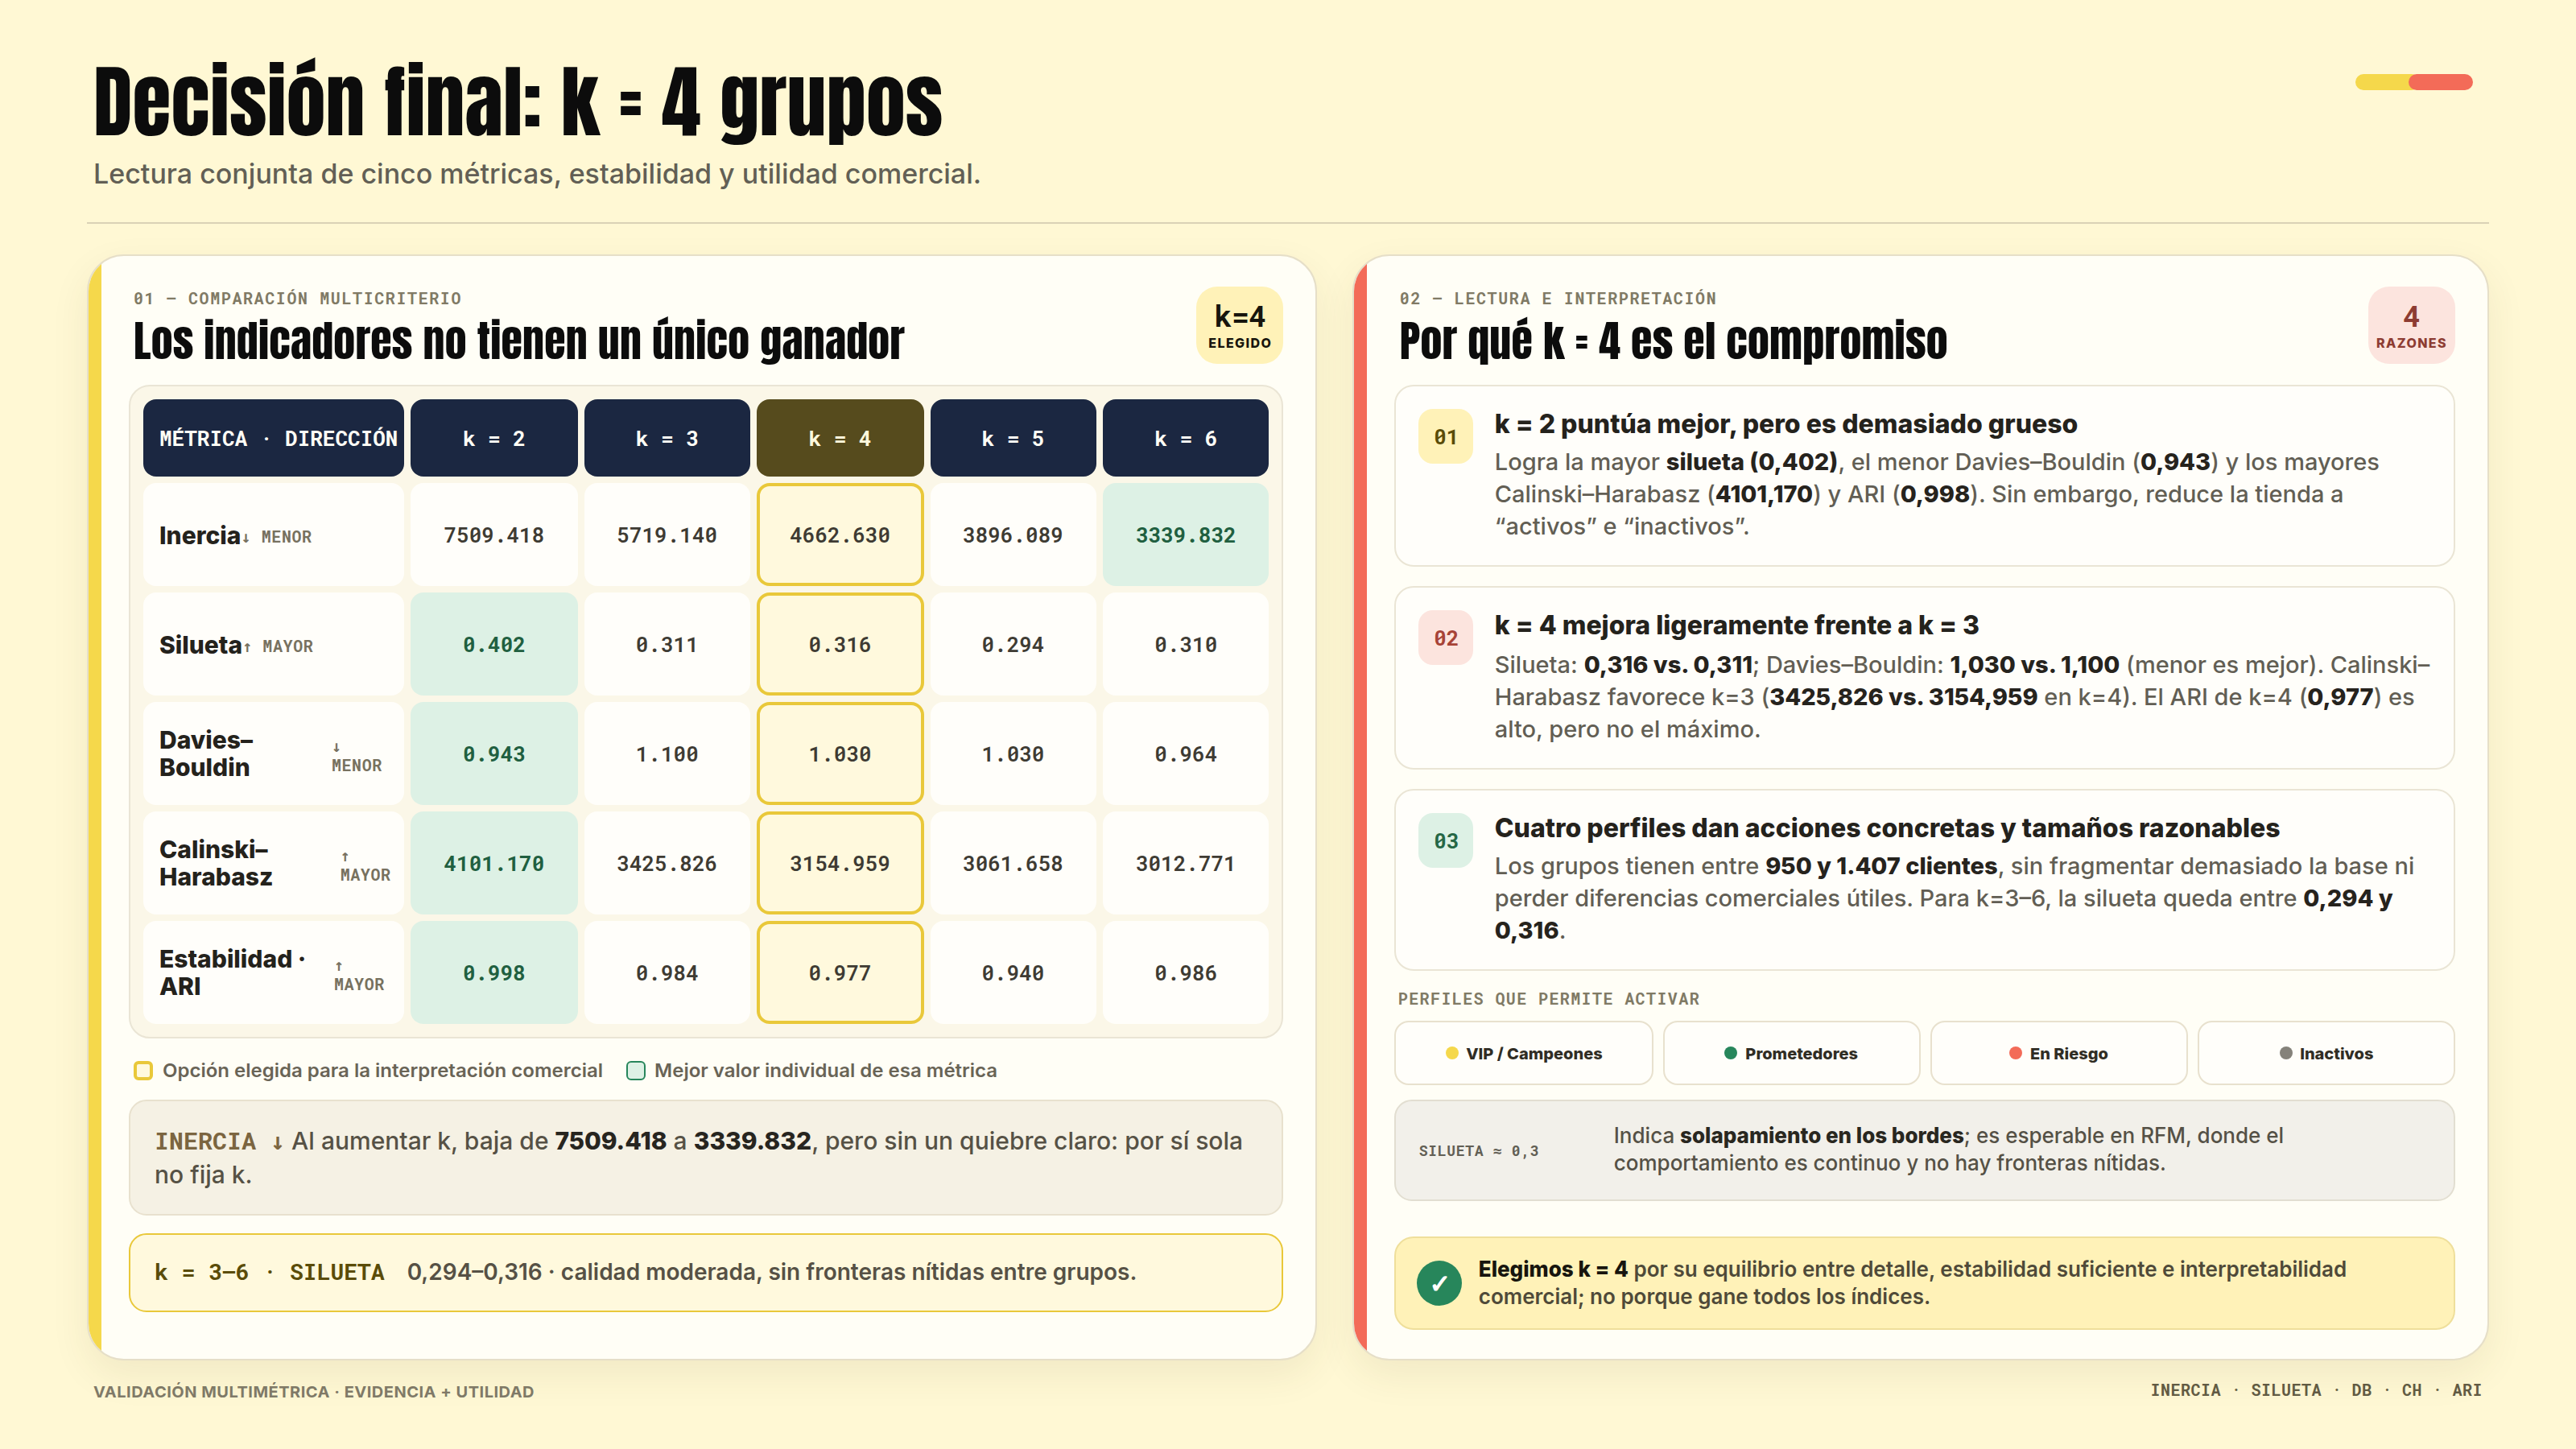

### **8️⃣ Aplicar K-Means e interpretar los grupos**
Ahora sí entrenamos el modelo definitivo de K-Means con `k = 4`. Cada cliente recibe su etiqueta de clúster (`0, 1, 2, 3`) y volvemos a los valores reales de **Recencia**, **Frecuencia** y **Monetario** para descubrir quiénes integran cada segmento y qué peso económico tienen en la empresa.

---

**🎯 Objetivos**
* 🤖 **Entrenar K-Means con k = 4:** asignar a cada uno de los 4.692 clientes su grupo correspondiente.
* 📋 **Construir el perfil real de cada segmento:** calcular los promedios de R, F, M, la cantidad de clientes y el porcentaje de ingresos totales que representa cada grupo.
* 👀 **Visualizar los clústeres y sus centroides en 3D:** comprobar gráficamente cómo quedaron separados en el espacio.


In [ ]:
# Configuramos el modelo K-Means con k = 4 grupos
# (n_init=10 prueba 10 posiciones iniciales distintas y se queda con la mejor)
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)

# AQUÍ OCURREN LAS ITERACIONES: fit_predict() ubica los 4 centroides, asigna cada cliente
# al más cercano y recalcula los centros repetidamente hasta que dejan de moverse (convergencia)
rfm["Cluster"] = kmeans_final.fit_predict(rfm_escalado)

# Calculamos los promedios reales de Recencia, Frecuencia y Monetario por grupo
resumen_grupos = rfm.groupby("Cluster")[["Recencia", "Frecuencia", "Monetario"]].mean().round(2)

# Agregamos la cantidad de clientes y qué porcentaje del total representa cada grupo
resumen_grupos["Clientes"] = rfm["Cluster"].value_counts().sort_index()
resumen_grupos["% Clientes"] = (resumen_grupos["Clientes"] / len(rfm) * 100).round(1)

# Calculamos qué porcentaje de los ingresos totales aporta cada grupo a la empresa
ingreso_por_grupo = rfm.groupby("Cluster")["Monetario"].sum()
resumen_grupos["% Ingresos"] = (ingreso_por_grupo / ingreso_por_grupo.sum() * 100).round(1)

# Mostramos cuántas vueltas necesitó para converger y la tabla resumen completa
print(f"Modelo finalizado en {kmeans_final.n_iter_} iteraciones.\n")
resumen_grupos

Modelo finalizado en 18 iteraciones.



,Recencia,Frecuencia,Monetario,Clientes,% Clientes,% Ingresos
Cluster,,,,,,
0,15.94,11.92,38150.11,950,20.2,64.7
1,99.12,3.17,10006.42,1407,30.0,25.1
2,203.90,1.22,1633.82,1379,29.4,4.0
3,19.96,2.27,3612.25,956,20.4,6.2


**💡 Nombre, peso en ingresos y robustez de cada segmento**

Nombramos los grupos a partir de sus valores (no de su número, que depende de la semilla), calculamos cuánto aportan a los ingresos y comparamos promedio vs. mediana: unos pocos clientes enormes pueden inflar el promedio.

In [ ]:
# Calculamos el perfil promedio de cada cluster (R, F y M)
perfil = rfm.groupby("Cluster")[["Recencia", "Frecuencia", "Monetario"]].mean()

# Creamos un diccionario vacío donde guardaremos el nombre de cada cluster
nombres = {}

# 1) El cluster con MAYOR gasto promedio son los Campeones
campeones = perfil["Monetario"].idxmax()
# Guardamos su nombre
nombres[campeones] = "VIP / Campeones"
# Quitamos ese cluster de la lista para no nombrarlo dos veces
restantes = perfil.drop(index=campeones)

# 2) De los que quedan, el de MAYOR recencia (más días sin comprar) son los Perdidos
perdidos = restantes["Recencia"].idxmax()
# Guardamos su nombre
nombres[perdidos] = "Inactivos"
# Quitamos ese cluster de la lista
restantes = restantes.drop(index=perdidos)

# 3) De los dos que quedan, el de MENOR recencia (compró hace menos) son los Recientes de bajo gasto
recientes = restantes["Recencia"].idxmin()
# Guardamos su nombre
nombres[recientes] = "Prometedores"
# Quitamos ese cluster de la lista
restantes = restantes.drop(index=recientes)

# 4) El único que queda son los Leales en enfriamiento
nombres[restantes.index[0]] = "En Riesgo"

# Agregamos el nombre del segmento a la tabla de clientes
rfm["Segmento"] = rfm["Cluster"].map(nombres)

# Peso de cada segmento en clientes e ingresos
resumen = rfm.groupby("Segmento").agg(
    Clientes=("Monetario", "size"),
    Ingreso_total=("Monetario", "sum"),
    Recencia_prom=("Recencia", "mean"),
    Frecuencia_prom=("Frecuencia", "mean"),
    Monetario_prom=("Monetario", "mean"),
    Recencia_med=("Recencia", "median"),
    Frecuencia_med=("Frecuencia", "median"),
    Monetario_med=("Monetario", "median"),
)
resumen["% Clientes"] = (resumen["Clientes"] / resumen["Clientes"].sum() * 100).round(1)
resumen["% Ingresos"] = (resumen["Ingreso_total"] / resumen["Ingreso_total"].sum() * 100).round(1)

resumen.sort_values("% Ingresos", ascending=False).round(1)

,Clientes,Ingreso_total,Recencia_prom,Frecuencia_prom,Monetario_prom,Recencia_med,Frecuencia_med,Monetario_med,% Clientes,% Ingresos
Segmento,,,,,,,,,,
VIP / Campeones,950,36242605.4,15.9,11.9,38150.1,11.0,8.0,20257.5,20.2,64.7
En Riesgo,1407,14079031.3,99.1,3.2,10006.4,75.0,3.0,7826.0,30.0,25.1
Prometedores,956,3453311.9,20.0,2.3,3612.3,18.0,2.0,2859.3,20.4,6.2
Inactivos,1379,2253031.5,203.9,1.2,1633.8,207.0,1.0,1376.9,29.4,4.0


**📊 Interpretación de los 4 segmentos**

K-Means convergió en 18 iteraciones y dividió a los 4.692 clientes en cuatro segmentos bien diferenciados:

---

🔴 **VIP / Campeones (`950 clientes` | `20,2 %` clientes | `64,7 %` ingresos)**  
* Compraron hace 16 días en promedio, acumulan 12 compras y un gasto de 38.150 (incluyendo a los compradores mayoristas). Son el principal sostén económico de la tienda.

---

🟠 **Prometedores (`956 clientes` | `20,4 %` clientes | `6,2 %` ingresos)**  
* Son clientes activos que compraron hace 20 días, pero todavía tienen pocas operaciones (2,3 compras) y un gasto bajo (3.612). Tienen alto potencial de crecimiento.

---

🟡 **En Riesgo (`1.407 clientes` | `30,0 %` clientes | `25,1 %` ingresos)**  
* Es el grupo más numeroso. Cuentan con un buen historial (3,2 compras y 10.006 de gasto promedio), pero llevan 99 días (más de 3 meses) sin volver a comprar.

---

⚪ **Inactivos (`1.379 clientes` | `29,4 %` clientes | `4,0 %` ingresos)**  
* Llevan casi 7 meses sin comprar (204 días), realizaron prácticamente una única compra (1,2) y tienen el menor gasto promedio (1.634).


In [ ]:
# 1. Preparamos la tabla con nombres claros de grupo y los valores reales para ver al pasar el mouse
datos_3d = rfm_escalado.copy()

# Usamos el nombre del segmento que ya calculamos en la celda anterior
datos_3d["Grupo"] = rfm["Segmento"]
datos_3d["Recencia_Real"] = rfm["Recencia"]
datos_3d["Frecuencia_Real"] = rfm["Frecuencia"]
datos_3d["Monetario_Real"] = rfm["Monetario"].round(2)

# Tomamos la muestra de 1000 clientes para mantener el gráfico ágil
muestra = datos_3d.sample(1000, random_state=42)

# 2. Dibujamos los clientes en 3D con paleta cálida
fig = px.scatter_3d(
    muestra, x="Recencia", y="Frecuencia", z="Monetario", color="Grupo",
    color_discrete_map={"VIP / Campeones": "#FF3D3D", "Prometedores": "#E67E22", "En Riesgo": "#F1C40F", "Inactivos": "#7F8C8D"},
    hover_data=["Recencia_Real", "Frecuencia_Real", "Monetario_Real"],
    title="<b>Segmentación Final y Centroides en 3D</b> (Clic en la leyenda para filtrar)"
)
fig.update_traces(marker=dict(size=4.5, opacity=0.85, line=dict(width=0.5, color="#1C2833")))

# 3. Agregamos los 4 centroides marcados con una cruz negra ('x')
centros = kmeans_final.cluster_centers_
fig.add_trace(go.Scatter3d(
    x=centros[:, 0], y=centros[:, 1], z=centros[:, 2], mode="markers+text",
    text=[nombres[i] for i in range(4)], textposition="top center", name="Centroides",
    marker=dict(size=9, color="black", symbol="x")
))

# 4. Aplicamos fondo #FFF8D4, aprovechamos el espacio y convertimos la leyenda en tarjeta/botones grandes
fig.update_layout(
    width=920, height=640, paper_bgcolor="#FFF8D4", margin=dict(l=10, r=10, t=55, b=10),
    legend=dict(
        title=dict(text="<b>Filtrar Grupos (clic):</b><br>", font=dict(size=13)),
        font=dict(size=13, color="#1C2833"),    # Letra más grande y legible
        itemsizing="constant",                  # Agranda los círculos de color para que parezcan botones
        bgcolor="#F9E79F",                      # Fondo amarillo suave tipo tarjeta/botón
        bordercolor="#D4AC0D",                  # Borde dorado definido
        borderwidth=1.5,
        itemclick="toggle",                     # Un clic oculta/muestra el grupo
        itemdoubleclick="toggleothers"          # Doble clic aísla solo ese grupo
    ),
    scene=dict(
        xaxis=dict(backgroundcolor="#F9E79F", gridcolor="white"),
        yaxis=dict(backgroundcolor="#FDEBD0", gridcolor="white"),
        zaxis=dict(backgroundcolor="#FADBD8", gridcolor="white"),
        camera=dict(eye=dict(x=1.45, y=1.45, z=1.15))
    )
)
fig.show()

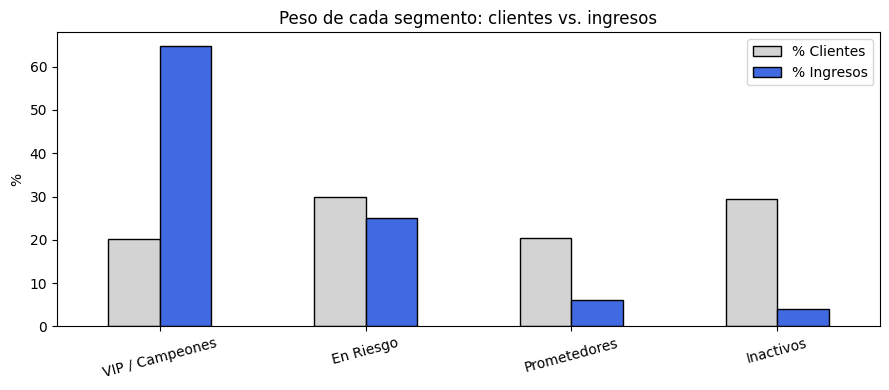

In [ ]:
# Gráfico: % de clientes vs % de ingresos por segmento
comp = resumen[["% Clientes", "% Ingresos"]].sort_values("% Ingresos", ascending=False)
ax = comp.plot(kind="bar", figsize=(9, 4), color=["lightgray", "royalblue"], edgecolor="black")
ax.set_title("Peso de cada segmento: clientes vs. ingresos")
ax.set_ylabel("%")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**🎯 Centroides en valores reales**

Los centroides del modelo están en escala logarítmica y estandarizada, difícil de leer. Los devolvemos a días, compras y dinero deshaciendo el escalado y el logaritmo.

In [ ]:
# Deshacemos el escalado y luego el logaritmo para ver los centroides en unidades reales
centros_reales = np.expm1(escalador.inverse_transform(kmeans_final.cluster_centers_))
centros_reales = pd.DataFrame(centros_reales, columns=["Recencia (días)", "Frecuencia (compras)", "Monetario"])
centros_reales.index = [nombres[i] for i in range(4)]
centros_reales.round(1)

,Recencia (días),Frecuencia (compras),Monetario
VIP / Campeones,10.4,9.6,22500.2
En Riesgo,79.9,2.9,7980.7
Inactivos,174.5,1.2,1037.3
Prometedores,15.7,2.1,2643.5


**📝 ¿Por qué los centroides dan valores distintos al promedio?**

Los centroides se calculan en escala logarítmica. Por eso, al deshacerla, dan valores menores que el promedio (por ejemplo, Campeones: ~22.500 de centroide frente a ~38.150 de promedio) y más parecidos a la **mediana**. El promedio se infla por unos pocos clientes enormes.

**✨ Calidad de cada grupo: silueta por cluster y proyección PCA**

* 📏 **Silueta por cluster:** muestra qué grupos están bien definidos y cuáles se mezclan con otros.

* 🗺️ **PCA en 2D:** resume las 3 variables en 2 ejes para ver la separación de los grupos en un gráfico plano.

Silueta promedio por segmento:
Segmento
Prometedores       0.260
En Riesgo          0.287
VIP / Campeones    0.336
Inactivos          0.371
dtype: float64

Clientes con silueta negativa (posiblemente mal asignados): 90 (1.9%)

Varianza explicada por PC1 + PC2: 91.4%


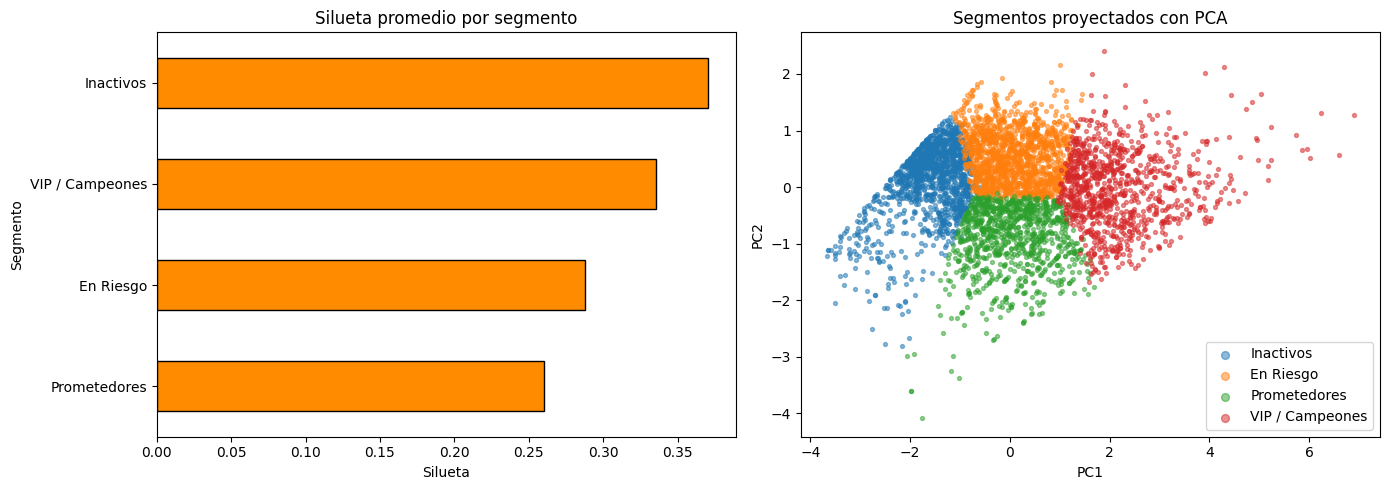

In [ ]:
from sklearn.metrics import silhouette_samples
from sklearn.decomposition import PCA

# Silueta individual de cada cliente y promedio por cluster
sil_clientes = silhouette_samples(rfm_escalado, rfm["Cluster"])
sil_por_grupo = pd.Series(sil_clientes, index=rfm.index).groupby(rfm["Segmento"]).mean().sort_values()
print("Silueta promedio por segmento:")
print(sil_por_grupo.round(3))
print(f"\nClientes con silueta negativa (posiblemente mal asignados): {(sil_clientes < 0).sum()} ({(sil_clientes < 0).mean()*100:.1f}%)")

# PCA a 2 componentes
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(rfm_escalado)
print(f"\nVarianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: silueta promedio por segmento
sil_por_grupo.plot(kind="barh", ax=ejes[0], color="darkorange", edgecolor="black")
ejes[0].set_title("Silueta promedio por segmento")
ejes[0].set_xlabel("Silueta")

# Gráfico 2: proyección PCA coloreada por segmento
for seg in rfm["Segmento"].unique():
    mask = (rfm["Segmento"] == seg).values
    ejes[1].scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=seg)
ejes[1].set_title("Segmentos proyectados con PCA")
ejes[1].set_xlabel("PC1")
ejes[1].set_ylabel("PC2")
ejes[1].legend(markerscale=2)

plt.tight_layout()
plt.show()

**🪪 Perfil relativo de cada segmento**

Un mapa de calor con el promedio estandarizado de R, F y M: rojo = por encima del promedio general, azul = por debajo. Para Recencia, **un valor alto es malo** (hace mucho que no compra).

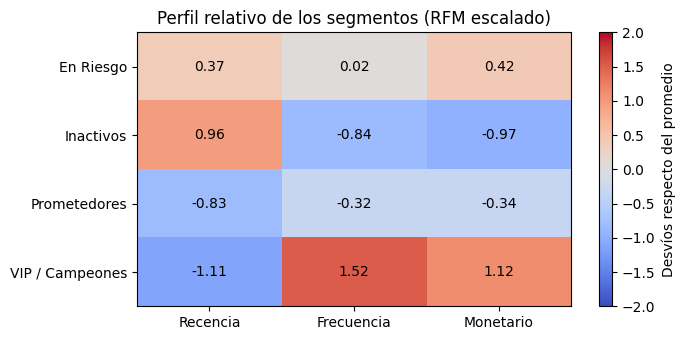

In [ ]:
# Promedio de las variables escaladas por segmento
perfil_rel = rfm_escalado.groupby(rfm["Segmento"]).mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
im = ax.imshow(perfil_rel.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(perfil_rel.columns)
ax.set_yticks(range(len(perfil_rel))); ax.set_yticklabels(perfil_rel.index)
for i in range(perfil_rel.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{perfil_rel.values[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, label="Desvíos respecto del promedio")
ax.set_title("Perfil relativo de los segmentos (RFM escalado)")
plt.tight_layout()
plt.show()

**🚫 Limitaciones de K-Means en este trabajo**

* Asume grupos **esféricos y de tamaño parecido**; los datos RFM son continuos, por eso hay solapamiento en los bordes.

* Es **sensible a outliers** (por eso aplicamos log) y a la **escala** (por eso estandarizamos).

* Hay que **fijar k de antemano**; la elección combina métricas y criterio de negocio.

* El resultado depende de la **inicialización** (por eso usamos `n_init=10` y comprobamos la estabilidad con ARI).

* Se podría comparar con otros algoritmos (Gaussian Mixture, clustering jerárquico, DBSCAN) como trabajo futuro.

### **9️⃣ Conclusión Final**
Segmentamos **4.692 clientes** de un e-commerce con K-Means (k = 4) a partir de sus variables RFM, previamente transformadas con logaritmo y estandarizadas. Los resultados de la ejecución fueron:

| Segmento | Clientes | % Clientes | % Ingresos | Recencia | Frecuencia | Monetario | Lectura |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **VIP / Campeones** | 950 | 20,2 % | 64,7 % | ~16 días | ~12 compras | ~38.150 | Compran seguido y mucho; aportan cerca de **dos tercios de los ingresos**. |
| **En Riesgo** | 1.407 | 30,0 % | 25,1 % | ~99 días | ~3 compras | ~10.000 | Buen valor, pero llevan más de tres meses sin comprar. |
| **Prometedores** | 956 | 20,4 % | 6,2 % | ~20 días | ~2 compras | ~3.600 | Compraron hace poco; con estímulo pueden crecer. |
| **Inactivos** | 1.379 | 29,4 % | 4,0 % | ~204 días | ~1 compra | ~1.630 | Compraron una vez y no volvieron; bajo retorno por inversión. |

---

**⚡ Acciones sugeridas**

Fidelizar a los VIP / Campeones (beneficios, acceso anticipado), reactivar cuanto antes a los en Riesgo (ofertas personalizadas), impulsar la segunda y tercera compra de los Recientes (venta cruzada) y limitar la inversión en los Inactivos.

---

**🤖 Sobre el modelo:**

k = 4 no maximiza la silueta (lo hace k = 2), pero ofrece segmentos interpretables y accionables. La silueta de ~0,32 indica grupos que se solapan en los bordes, algo habitual en RFM. Para consolidar los hallazgos conviene validar los segmentos con datos de períodos posteriores.


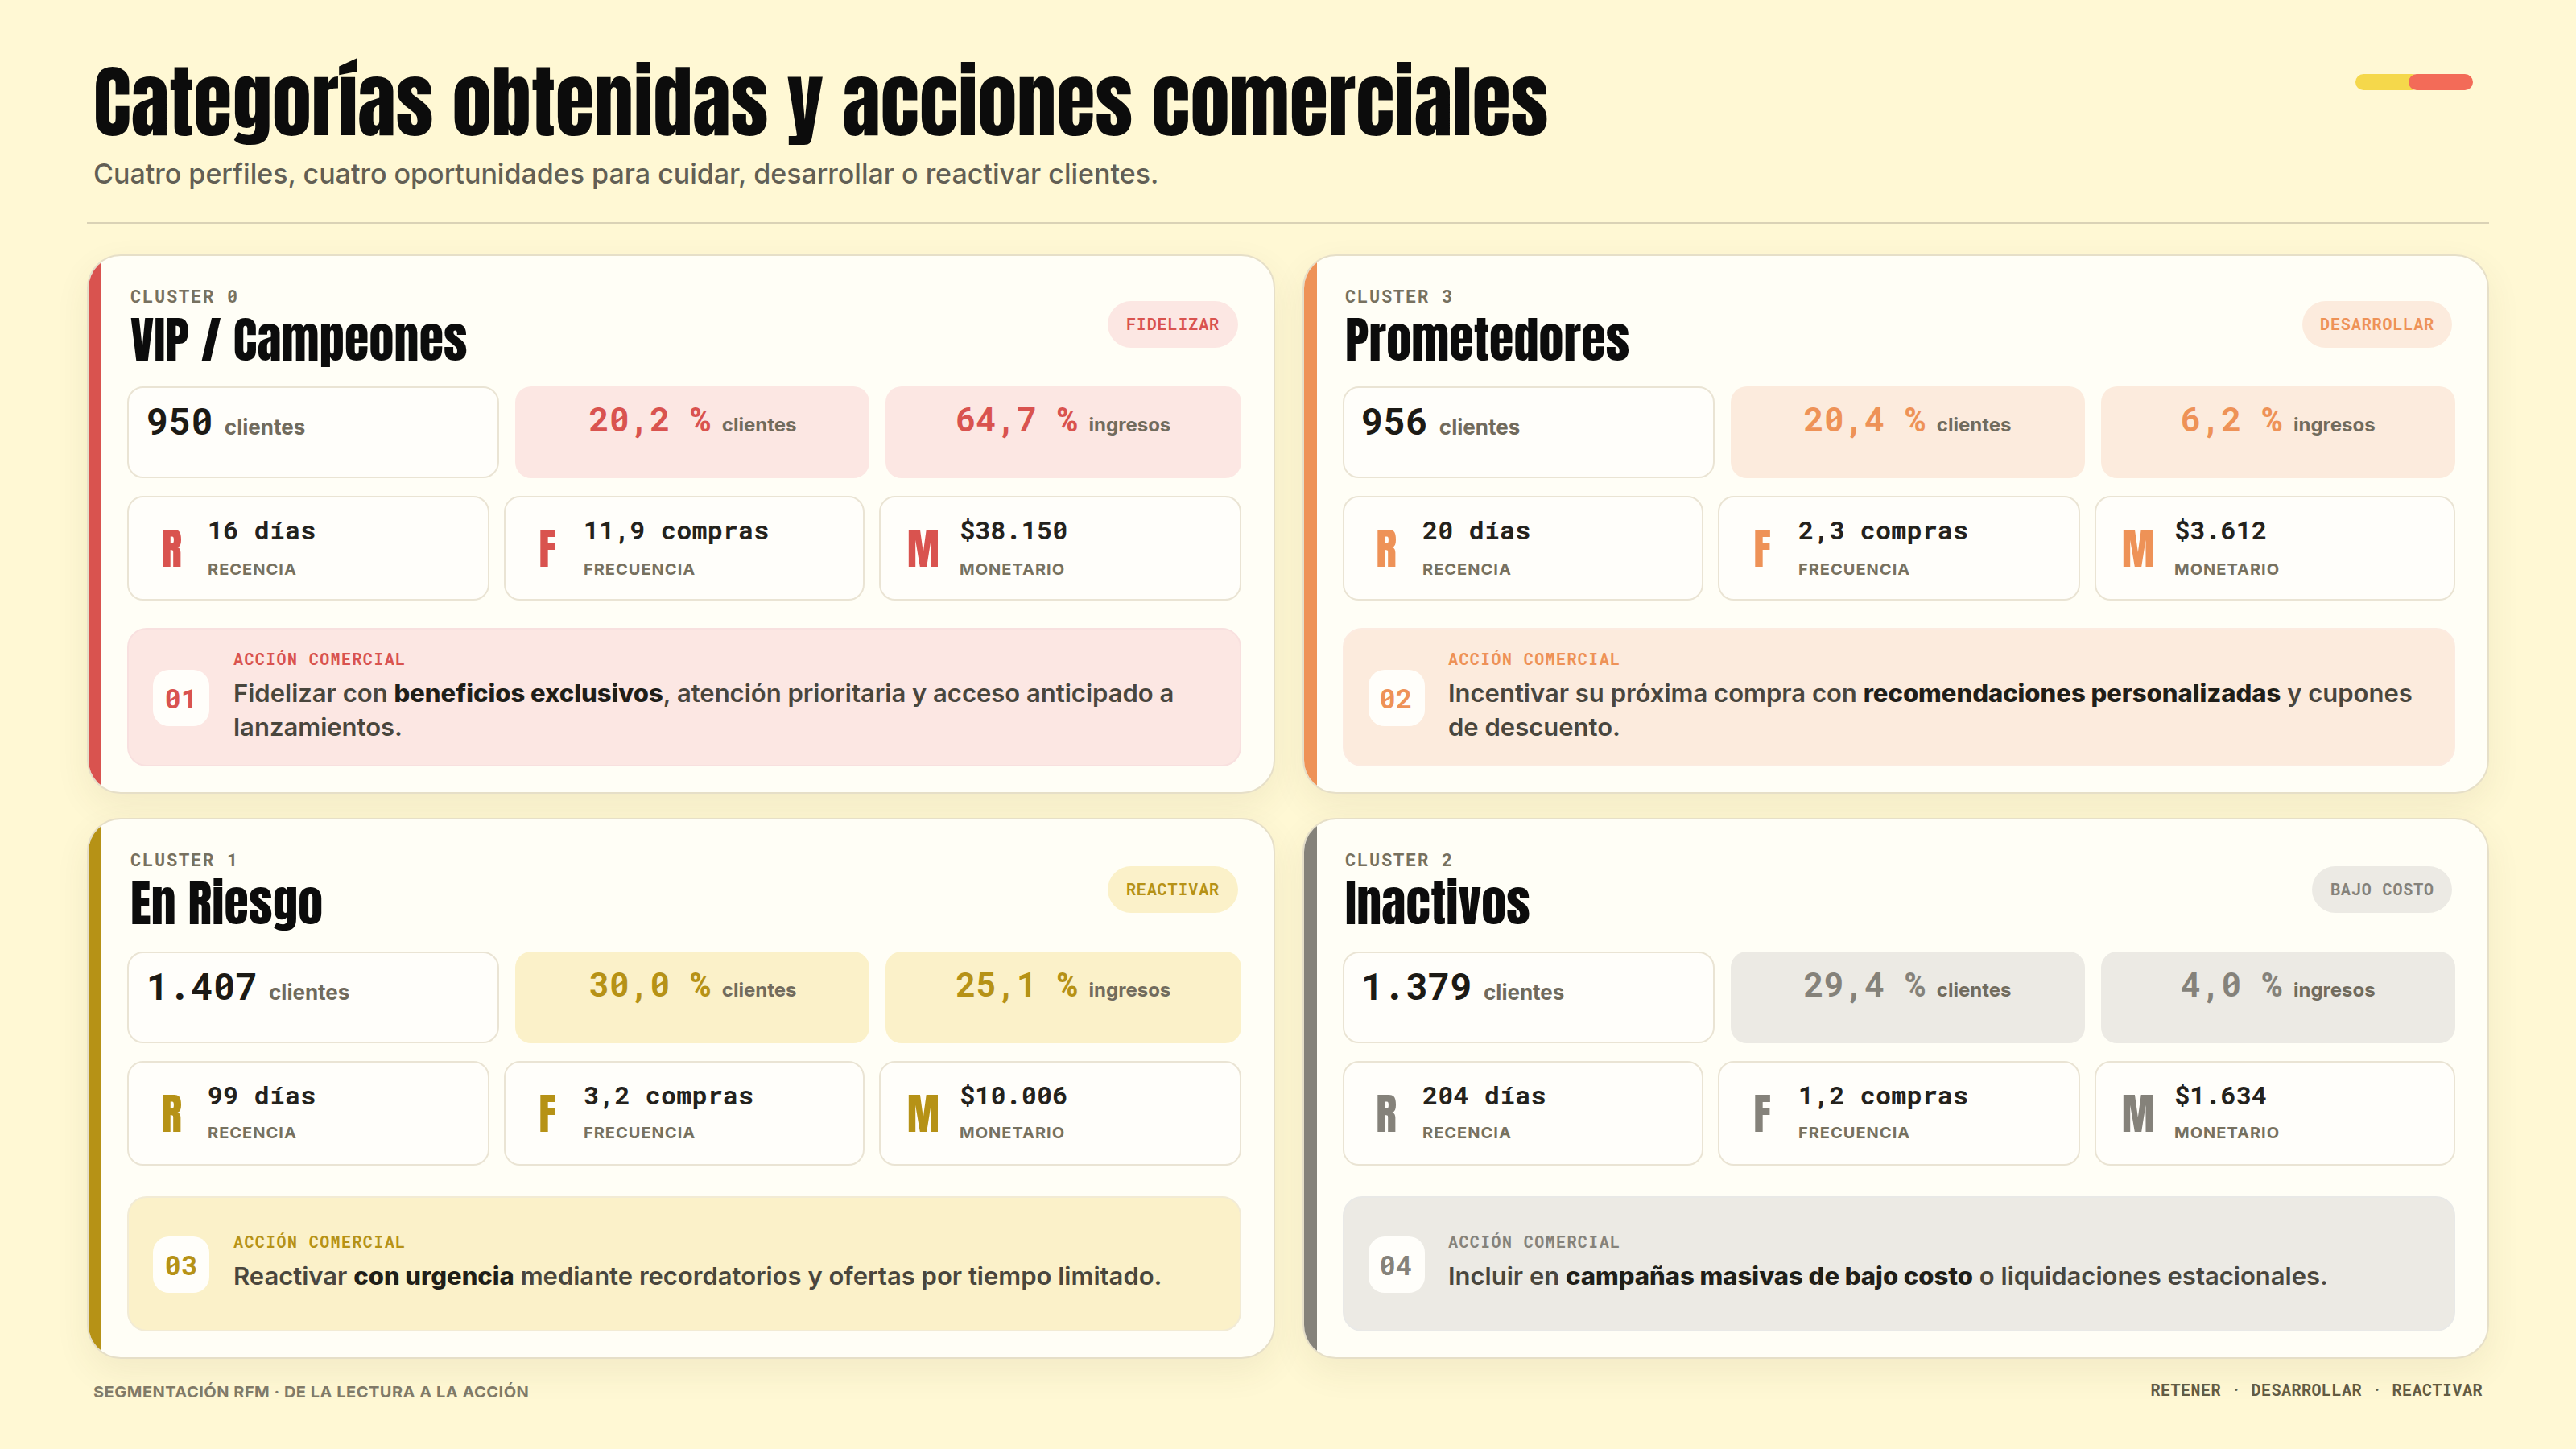